# Combined vs separate — analysis across all three experiments

Pick an experiment with `EXPERIMENT` below. All three that have been run so far are wired up:

| key | what it is | runs |
|---|---|---|
| `sweep-400ep` | folder 12's training-method sweep: 16 hyperparameter cells x 2 archs x 2 seeds x 4 thresholds, 400 epochs | 254 |
| `long-1000ep-a` | first long run: adam lr=0.003 b=256 init=normal, 7 thresholds, 1 seed, 1000 epochs | 14 |
| `long-1000ep-b` | second long run: adam lr=0.006 b=128 init=normal, 5 thresholds, 1 seed, 1000 epochs | 10 |

Where an experiment has **multiple seeds** the curves are seed-averaged (individual seeds shown
as faint dots). Where it has **multiple hyperparameter cells**, `CELL` selects one for the detail
figures, and a dedicated section compares *all* cells at once.

Reference predictors are computed per split and cached per (split, threshold-set):
`ideal-alpha` (knows the true table -- the floor), **`context-Bayes`** (the exact posterior
predictive under this generator's prior -- the true ceiling for any context-only predictor),
`ctx-count` (add-eps counts), and the in-arch hand construction.

Every series carries its own colour **and** marker **and** linestyle (Okabe-Ito CVD-safe family),
so identity never rests on colour alone.


In [3]:
import csv, glob, importlib.util, json, os
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt

# ── EDIT HERE ────────────────────────────────────────────────────────────────
EXPERIMENT = 'long-1000ep-a'      # 'sweep-400ep' | 'long-1000ep-a' | 'long-1000ep-b'
CELL       = None                 # None -> the experiment's default cell; or an explicit cell tag
# ─────────────────────────────────────────────────────────────────────────────

_F12 = os.path.join('..', '12. training level exhaustive experiment to confirm finding')
EXPERIMENTS = {
    'sweep-400ep':   dict(runs=os.path.join(_F12, 'runs'), cell=None,
                          note='16 cells x 2 archs x 2 seeds x 4 thresholds, 400 ep'),
    'long-1000ep-a': dict(runs='runs', cell='opt-adam_lr-0.003_b-256_init-normal_ep-1000',
                          note='adam lr=0.003 b=256, 7 thresholds, 1 seed, 1000 ep'),
    'long-1000ep-b': dict(runs='runs', cell='opt-adam_lr-0.006_b-128_init-normal_ep-1000',
                          note='adam lr=0.006 b=128, 5 thresholds, 1 seed, 1000 ep'),
}
EXP = EXPERIMENTS[EXPERIMENT]
RUNS_DIR = EXP['runs']

DIVERGE_CUTOFF = 5.0    # nats; healthy curves live in ~[0,2.4]. Guards the rare Adam spike
                        # (folder 12 had 7 such runs, all separate, thr=1.0, adam lr=0.01).

# RUNS[(cell, arch, thr)] = [metrics, ...] one per seed
RUNS = defaultdict(list)
for mp in sorted(glob.glob(os.path.join(RUNS_DIR, '*', 'metrics_*.json'))):
    m = json.load(open(mp))
    h = m['history']
    m.setdefault('final_train', h['train_loss'][-1])   # folder 12 predates these fields
    m.setdefault('final_test',  h['test_loss'][-1])
    RUNS[(m['cell'], m['arch'], m['threshold'])].append(m)
for v in RUNS.values():
    v.sort(key=lambda m: m['seed'])

ALL_CELLS = sorted({c for c, _, _ in RUNS})
if CELL is None:
    CELL = EXP['cell'] or ALL_CELLS[0]
assert CELL in ALL_CELLS, f'{CELL!r} not in {ALL_CELLS}'

ARCHS = ['combined', 'separate']
THRS  = sorted({t for c, _, t in RUNS if c == CELL})
SEEDS = sorted({m['seed'] for v in RUNS.values() for m in v})
# take the config from whichever architecture this cell actually has -- some cells
# (e.g. the factorized transplant) contain only one arch, so assuming 'combined' here
# raised a KeyError and left CFG undefined for every downstream cell.
CFG   = next(RUNS[k][0]['config'] for k in RUNS if k[0] == CELL)

ARTIFACTS_DIR = os.path.join('artifacts', EXPERIMENT, CELL)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

print(f"EXPERIMENT = {EXPERIMENT!r}   ({EXP['note']})")
print(f'runs dir   : {RUNS_DIR}')
print(f'cells      : {len(ALL_CELLS)}   seeds: {SEEDS}   thresholds: {THRS}')
print(f'selected   : CELL = {CELL!r}')
print(f"config     : {CFG['optimizer']} lr={CFG['lr']} b={CFG['batch_size']} init={CFG['init']} "
      f"epochs={CFG['epochs']}")
print(f'artifacts  : {ARTIFACTS_DIR}/')
if len(ALL_CELLS) > 1:
    print(f'\n({len(ALL_CELLS)} cells available -- the all-cells section below compares them;')
    print(' set CELL to any of these for the detail figures:)')
    for c in ALL_CELLS: print(f'   {c}')

def runs_of(arch, thr, cell=None):
    """All seeds for one (arch, threshold), diverged trajectories dropped."""
    return [m for m in RUNS[(cell or CELL, arch, thr)]
            if max(m['history']['train_loss']) <= DIVERGE_CUTOFF]

def agg(arch, thr, key, cell=None):
    """(mean over seeds, [per-seed values]) for a scalar metric."""
    vals = [m[key] for m in runs_of(arch, thr, cell)]
    return (float(np.mean(vals)) if vals else float('nan')), vals

print(f"\n{'thr':>5s} {'arch':>9s} {'n':>2s} {'best_train':>11s} {'test@best':>10s} "
      f"{'final_te':>9s} {'epochs':>7s}")
for t in THRS:
    for a in ARCHS:
        rs = runs_of(a, t)
        if not rs: continue
        bt, _ = agg(a, t, 'best_train'); tb, _ = agg(a, t, 'test_at_best')
        ft, _ = agg(a, t, 'final_test')
        print(f"{t:5.1f} {a:>9s} {len(rs):2d} {bt:11.4f} {tb:10.4f} {ft:9.4f} "
              f"{int(np.mean([m['epochs_run'] for m in rs])):7d}")
n_drop = sum(len(v) for v in RUNS.values()) - sum(
    len(runs_of(a, t)) for t in THRS for a in ARCHS)


EXPERIMENT = 'long-1000ep-a'   (adam lr=0.003 b=256, 7 thresholds, 1 seed, 1000 ep)
runs dir   : runs
cells      : 18   seeds: [0]   thresholds: [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
selected   : CELL = 'opt-adam_lr-0.003_b-256_init-normal_ep-1000'
config     : adam lr=0.003 b=256 init=normal epochs=1000
artifacts  : artifacts/long-1000ep-a/opt-adam_lr-0.003_b-256_init-normal_ep-1000/

(18 cells available -- the all-cells section below compares them;
 set CELL to any of these for the detail figures:)
   factorized-from-combined_ep-100
   hi-lr_opt-adam_lr-0.008_b-128_init-normal_ep-400
   hi-lr_opt-adam_lr-0.015_b-128_init-normal_ep-400
   hi-lr_opt-adam_lr-0.01_b-128_init-normal_ep-400
   hi-lr_opt-adam_lr-0.025_b-128_init-normal_ep-400
   hi-lr_opt-adam_lr-0.02_b-128_init-normal_ep-400
   hi-lr_opt-adam_lr-0.035_b-128_init-normal_ep-400
   hi-lr_opt-adam_lr-0.03_b-128_init-normal_ep-400
   hi-lr_opt-adam_lr-0.045_b-128_init-normal_ep-400
   hi-lr_opt-adam_lr-0.04_b-128_init-normal_ep-4

## Reference predictors (no training)

Ported from folder 11's `simplified_setting.ipynb`. Computed on **both** splits and cached to
`artifacts/baseline_ce_cache.json`, keyed by (split, threshold-set, eps) so different experiments
with different threshold lists coexist without evicting each other.

The construction forward pass runs on **CPU** and in chunks — this box's GPUs are often saturated,
and the full split would otherwise materialise a huge attention tensor at once.


In [2]:
SPLITS = ['train', 'test']
DATA_DIR    = os.path.join(_F12, 'dataset')
TOKEN_START = CFG['token_start']
TOKEN_END   = CFG['seq_len']
CONSTRUCTION_EPS = 0.01     # folder-11 convention. NOTE: not the optimal smoothing -- see below.
BASELINE_BATCH   = 256

_spec = importlib.util.spec_from_file_location('t14', 'train.py')
_t14 = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(_t14)
SimplifiedTransformerMLP = _t14.SimplifiedTransformerMLP

def load_blob(split, thr):
    return torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)

def ideal_alpha_dist(blob, alpha):
    """Knows the true 2-successor table AND its probabilities -> the CE floor."""
    x_np = blob['x'].numpy(); trans = blob['transitions']; probs = blob['trans_probs']
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_arr = np.array([[trans[b][v] for v in range(Vs)] for b in range(B)], dtype=np.int64)
    prob_arr  = np.array([[probs[b][v] for v in range(Vs)] for b in range(B)], dtype=np.float64)
    p_win = np.zeros((B, W, V_)); last_sig = np.zeros(B, dtype=np.int64)
    for t in range(TOKEN_END):
        is_sig = x_np[:, t] < Vs
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < TOKEN_START: continue
        ar = np.arange(B)
        s0, s1 = trans_arr[ar, last_sig, 0], trans_arr[ar, last_sig, 1]
        q0, q1 = prob_arr[ar, last_sig, 0],  prob_arr[ar, last_sig, 1]
        p = np.zeros((B, V_)); p[:, Vs:] = (1.0 - alpha) / n_noise
        p[ar, s0] += alpha * q0; p[ar, s1] += alpha * q1
        p_win[:, t - TOKEN_START] = p
    return p_win

def ctx_count_dist(blob, alpha, eps=0.01):
    """Empirical successor counts of the current state, smoothed by eps, scaled by alpha, plus
    the exact noise floor == what a perfect induction head outputs."""
    x_np = blob['x'].numpy()
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts = np.zeros((B, V_, Vs)); pending = np.zeros((B, V_))
    last_ruled = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok = x_np[:, col]; is_sig = tok < Vs
        ri = np.where(is_sig)[0]
        if len(ri):
            rt = tok[ri]
            oh = (np.arange(Vs) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_sig)[0]
        if len(ni): pending[ni, tok[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    p_win = np.zeros((B, W, V_))
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]
        q = np.where(v < Vs, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), q] + eps
        p = np.zeros((B, V_))
        p[:, :Vs] = cnt / cnt.sum(axis=1, keepdims=True) * alpha
        p[:, Vs:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        _step(t)
    return p_win

import itertools, functools

_PAIRS = list(itertools.combinations(range(CFG['v_sig']), 2))   # the 6 unordered successor pairs
_QG  = np.linspace(0.1, 0.9, 401)                               # q ~ U(0.1,0.9) from data_generation
_LQ, _L1Q = np.log(_QG), np.log(1 - _QG)

@functools.lru_cache(maxsize=None)
def _bayes_pred(n_tup):
    """Exact posterior predictive over the signal states given this state's successor counts.
    (1) eliminate every successor-pair that misses an observed successor -> those tokens get
    EXACTLY zero; (2) weigh each surviving pair by q^{n_a}(1-q)^{n_b}, the likelihood of the
    counts; (3) average the pairs' predictions. Rows are drawn independently per state in
    data_generation.py, so the current state's counts are a sufficient statistic."""
    Vs_ = len(n_tup)
    n = np.array(n_tup, float)
    valid = [(a, b) for a, b in _PAIRS
             if not any(n[j] > 0 for j in range(Vs_) if j not in (a, b))]
    if not valid:
        return np.ones(Vs_) / Vs_
    logs = [n[a] * _LQ + n[b] * _L1Q for a, b in valid]
    C = max(l.max() for l in logs)          # stabilise: q**50 underflows in float64
    num = np.zeros(Vs_); den = 0.0
    for (a, b), l in zip(valid, logs):
        w = np.exp(l - C)
        den    += w.sum()
        num[a] += (w * _QG).sum()
        num[b] += (w * (1 - _QG)).sum()
    return num / den

def true_bayes_dist(blob, alpha):
    """Bayes-OPTIMAL context-only predictor for THIS generator (2-of-4 successors, split
    q~U(0.1,0.9)). Identical count bookkeeping to ctx_count_dist -- only the readout differs,
    so any gap between the two curves is purely the estimator, not the statistics."""
    x_np = blob['x'].numpy()
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts = np.zeros((B, V_, Vs)); pending = np.zeros((B, V_))
    last_ruled = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok = x_np[:, col]; is_sig = tok < Vs
        ri = np.where(is_sig)[0]
        if len(ri):
            rt = tok[ri]
            oh = (np.arange(Vs) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_sig)[0]
        if len(ni): pending[ni, tok[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    p_win = np.zeros((B, W, V_))
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]
        q = np.where(v < Vs, v, np.maximum(last_ruled, 0))
        rows = trans_counts[np.arange(B), q]
        p = np.zeros((B, V_))
        p[:, :Vs] = np.array([_bayes_pred(tuple(r)) for r in rows]) * alpha
        p[:, Vs:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        _step(t)
    return p_win


def _build_construction_attn(V, T, Vs, dev):
    """Hand-set combined Wqk/Wov implementing folder 10's PerfectInductionTransformer circuit,
    converted to combined form via W_qk = Wq^T@Wk, W_ov = Wv^T@Wo^T (exact reparametrization)."""
    D = V + T
    Wq1 = torch.eye(D, device=dev) * (D ** 0.5)
    T1 = torch.zeros(D, D, device=dev)
    for k in range(Vs, V): T1[k, :] = -1e9
    for tq in range(T):
        for tk in range(T):
            T1[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)
    Wk1 = T1.t()
    Wv1 = torch.zeros(D, D, device=dev); Wv1[:V, :V] = torch.eye(V, device=dev)
    Wo1 = torch.eye(D, device=dev)
    in2 = D + D
    Wq2 = torch.zeros(D, in2, device=dev)
    Wq2[:Vs, :Vs]    = torch.eye(Vs, device=dev) * (D ** 0.5) * 1000.0
    Wq2[:Vs, D:D+Vs] = torch.eye(Vs, device=dev) * (D ** 0.5) * 50.0
    for v in range(V): Wq2[Vs, v] = (D ** 0.5) * 10.0
    Wk2 = torch.zeros(D, in2, device=dev); Wk2[:V, D:D+V] = torch.eye(V, device=dev)
    for v in range(Vs, V): Wk2[Vs, v] = -50000.0
    Wv2 = torch.zeros(D, in2, device=dev); Wv2[:V, :V] = torch.eye(V, device=dev)
    Wo2 = torch.eye(D, device=dev)
    return Wq1.t() @ Wk1, Wv1.t() @ Wo1.t(), Wq2.t() @ Wk2, Wv2.t() @ Wo2.t()

_CONSTRUCTION_CACHE = {}

def build_construction_model(V, T, Vs, dev):
    m = SimplifiedTransformerMLP(V, T, V + T, Vs, CFG['freeze_hidden_k'], bias=True,
                                 attn_param='combined').to(dev)
    Wqk1, Wov1, Wqk2, Wov2 = _build_construction_attn(V, T, Vs, dev)
    with torch.no_grad():
        m.layer1.W_qk.copy_(Wqk1); m.layer1.W_ov.copy_(Wov1)
        m.layer2.W_qk.copy_(Wqk2); m.layer2.W_ov.copy_(Wov2)
        m.ff2.weight.zero_(); m.ff2.bias.zero_()                        # dormant FFN
        m.fc_out.weight.zero_()
        m.fc_out.weight[:V, m.in2:m.in2 + V] = torch.eye(V, device=dev)   # identity selector
        m.fc_out.bias.zero_()
    for p in m.parameters(): p.requires_grad_(False)
    m.eval(); return m

@torch.no_grad()
def construction_dist(blob, alpha, eps=CONSTRUCTION_EPS, dev=torch.device('cpu')):
    V = blob['total_vocab']; Vs = blob['vocab_set1']; T = blob['seq_len']
    key = (V, T, Vs, str(dev))
    if key not in _CONSTRUCTION_CACHE:
        _CONSTRUCTION_CACHE[key] = build_construction_model(V, T, Vs, dev)
    logits = _CONSTRUCTION_CACHE[key](blob['x'].to(dev))[:, TOKEN_START:TOKEN_END]
    f = logits[..., :Vs].clamp_min(0.0)
    psig = alpha * (f + eps) / (f + eps).sum(-1, keepdim=True)
    pn = torch.full(psig.shape[:-1] + (V - Vs,), (1.0 - alpha) / (V - Vs), device=psig.device)
    return torch.cat([psig, pn], dim=-1).cpu().numpy()

def _ce_from_win(p_win, y_np):
    yw = y_np[:, TOKEN_START:TOKEN_END]; B, W = yw.shape
    bb = np.arange(B)[:, None]; ww = np.arange(W)[None, :]
    return float((-np.log(np.maximum(p_win[bb, ww, yw], 1e-12))).mean())

def _construction_ce_chunked(blob, alpha, batch=BASELINE_BATCH):
    """Chunked so a large split never materialises a full [B,T,T] tensor at once."""
    x_all, y_all = blob['x'], blob['y']
    tot_nll = tot_n = 0
    for i in range(0, x_all.shape[0], batch):
        sub = dict(blob); sub['x'] = x_all[i:i + batch]; sub['y'] = y_all[i:i + batch]
        p = construction_dist(sub, alpha)
        yw = sub['y'].numpy()[:, TOKEN_START:TOKEN_END]; b, w = yw.shape
        bb = np.arange(b)[:, None]; ww = np.arange(w)[None, :]
        tot_nll += -np.log(np.maximum(p[bb, ww, yw], 1e-12)).sum(); tot_n += b * w
    return tot_nll / tot_n

# ── compute (or load) the baselines, per split ───────────────────────────────
CACHE_PATH = os.path.join('artifacts', 'baseline_ce_cache.json')
os.makedirs('artifacts', exist_ok=True)
cache_all = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}
if 'thresholds' in cache_all:                       # migrate the oldest flat format
    cache_all = {cache_all.get('split', 'test'): cache_all}

def _ckey(split):
    """Keyed by threshold-set too, so experiments with different alpha lists coexist."""
    return f"{split}|{','.join(str(t) for t in THRS)}|{CONSTRUCTION_EPS}"

BASE_CE = {}
for split in SPLITS:
    k = _ckey(split)
    entry = cache_all.get(k)
    if entry is None and cache_all.get(split, {}).get('thresholds') == THRS \
            and cache_all.get(split, {}).get('eps') == CONSTRUCTION_EPS:
        entry = cache_all[split]                    # reuse a legacy split-only entry
        cache_all[k] = entry
    if entry is not None and 'bayes' not in entry:
        print(f'back-filling true-Bayes for the {split} split (other baselines reused)...')
        entry['bayes'] = [_ce_from_win(true_bayes_dist(load_blob(split, t), t),
                                       load_blob(split, t)['y'].numpy()) for t in THRS]
        cache_all[k] = entry
        json.dump(cache_all, open(CACHE_PATH, 'w'), indent=2)
    if entry is None:
        print(f'computing baselines on the {split} split (CPU, chunked)...')
        ideal, ctx, constr, bayes = [], [], [], []
        for t in THRS:
            blob = load_blob(split, t); y_np = blob['y'].numpy()
            ideal.append(_ce_from_win(ideal_alpha_dist(blob, t), y_np))
            bayes.append(_ce_from_win(true_bayes_dist(blob, t), y_np))
            ctx.append(_ce_from_win(ctx_count_dist(blob, t), y_np))
            constr.append(_construction_ce_chunked(blob, t))
            print(f'  thr={t}: ideal={ideal[-1]:.4f} bayes={bayes[-1]:.4f} '
                  f'ctx={ctx[-1]:.4f} constr={constr[-1]:.4f}', flush=True)
        entry = {'thresholds': THRS, 'eps': CONSTRUCTION_EPS, 'split': split,
                 'ideal': ideal, 'bayes': bayes, 'ctx': ctx, 'construction': constr}
        cache_all[k] = entry
        json.dump(cache_all, open(CACHE_PATH, 'w'), indent=2)
        print(f'cached -> {CACHE_PATH} [{k}]')
    else:
        print(f'loaded cached baselines <- {CACHE_PATH} [{k}]')
    BASE_CE[split] = entry

IDEAL_CE  = BASE_CE['test']['ideal']
BAYES_CE  = BASE_CE['test']['bayes']
CTX_CE    = BASE_CE['test']['ctx']
CONSTR_CE = BASE_CE['test']['construction']


loaded cached baselines <- artifacts/baseline_ce_cache.json [train|0.4,0.5,0.6,0.7,0.8,0.9,1.0|0.01]
loaded cached baselines <- artifacts/baseline_ce_cache.json [test|0.4,0.5,0.6,0.7,0.8,0.9,1.0|0.01]


## 1. CE vs alpha — train and test side by side

Both panels come from the **same** best-train checkpoint (`best_train` on the left,
`test_at_best` on the right), so they show one model state from two angles rather than two
different models. Shared y-axis, so the panels are directly comparable by eye. With multiple
seeds the line is the seed mean and the faint dots are individual seeds.

**context-Bayes is the real bound.** `ctx-count` is just add-eps smoothing — Bayes-optimal only
under a Dirichlet prior, which this generator is not. The true posterior (a) puts *exactly zero*
on the two structurally impossible successors once both real ones are seen, and (b) never lets a
successor exceed q=0.9, so it keeps mass on an as-yet-unobserved second successor. No eps can do
either. A trained model landing between ctx-count and context-Bayes is therefore expected, not
anomalous; landing *below* context-Bayes would be impossible.


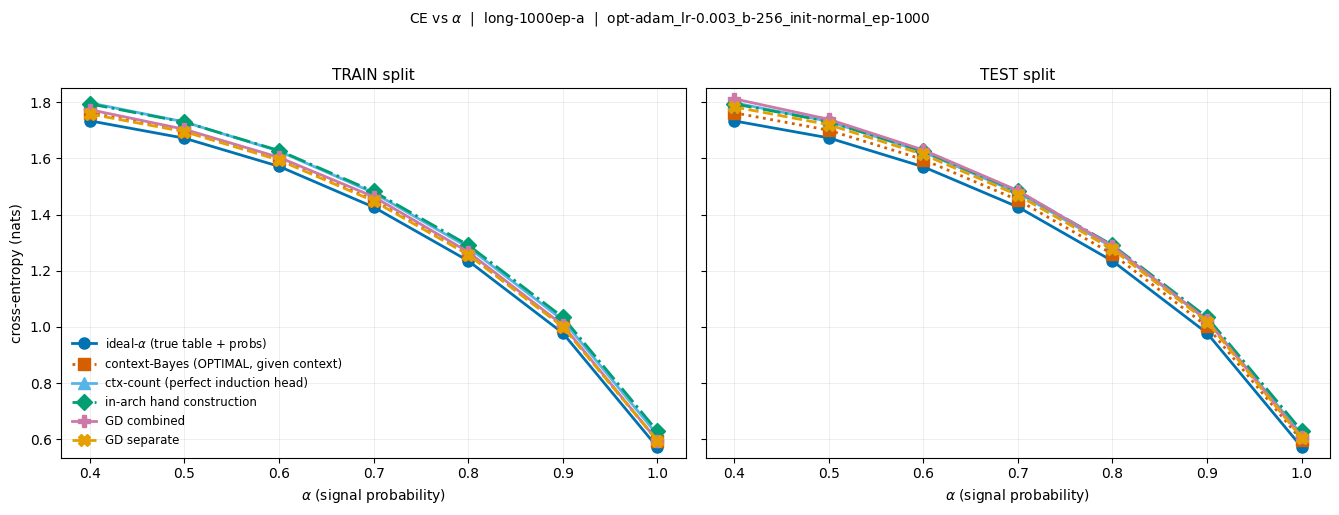


=== TRAIN split (models at their best-train checkpoint) ===
  thr    ideal    BAYES      ctx   constr  combined  separate  comb-sep  sep-Bayes
  0.4   1.7339   1.7627   1.7978   1.7943    1.7738    1.7584   +0.0154    -0.0043
  0.5   1.6721   1.6991   1.7301   1.7293    1.7037    1.6953   +0.0085    -0.0038
  0.6   1.5718   1.5977   1.6259   1.6281    1.6039    1.5943   +0.0096    -0.0034
  0.7   1.4266   1.4520   1.4776   1.4825    1.4638    1.4483   +0.0155    -0.0037
  0.8   1.2355   1.2599   1.2834   1.2915    1.2673    1.2571   +0.0102    -0.0028
  0.9   0.9782   1.0024   1.0242   1.0346    1.0064    1.0003   +0.0060    -0.0021
  1.0   0.5713   0.5949   0.6157   0.6285    0.5947    0.5950   -0.0003    +0.0001
fraction of the ctx-count -> Bayes gap closed:
    thr=0.4: combined   68.5%   separate  112.4%
    thr=0.5: combined   85.1%   separate  112.4%
    thr=0.6: combined   78.0%   separate  112.1%
    thr=0.7: combined   53.9%   separate  114.4%
    thr=0.8: combined   68.9%   

In [3]:
# Okabe-Ito CVD-safe family; each series also has its own marker + linestyle so identity never
# depends on colour alone (validated: normal-vision dE 18.4, worst CVD dE 7.6 + secondary encoding)
SERIES = {
    'ideal':        dict(color='#0072B2', marker='o', ls='-',  label=r'ideal-$\alpha$ (true table + probs)'),
    'bayes':        dict(color='#D55E00', marker='s', ls=':',  label='context-Bayes (OPTIMAL, given context)'),
    'ctx':          dict(color='#56B4E9', marker='^', ls='-',  label='ctx-count (perfect induction head)'),
    'construction': dict(color='#009E73', marker='D', ls='-.', label='in-arch hand construction'),
    'combined':     dict(color='#CC79A7', marker='P', ls='-',  label='GD combined'),
    'separate':     dict(color='#E69F00', marker='X', ls='--', label='GD separate'),
}
MODEL_KEY = {'train': 'best_train', 'test': 'test_at_best'}

def model_series(arch, split, cell=None):
    """(means, per-seed scatter points) across thresholds."""
    means, pts = [], []
    for t in THRS:
        mu, vals = agg(arch, t, MODEL_KEY[split], cell)
        means.append(mu); pts += [(t, v) for v in vals]
    return means, pts

_all = [v for sp in SPLITS for v in
        (BASE_CE[sp]['ideal'] + BASE_CE[sp]['bayes'] + BASE_CE[sp]['ctx'] +
         BASE_CE[sp]['construction'] +
         model_series('combined', sp)[0] + model_series('separate', sp)[0])]
_all = [v for v in _all if np.isfinite(v)]
pad = 0.03 * (max(_all) - min(_all))
ylim = (min(_all) - pad, max(_all) + pad)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), sharey=True)
for ax, split in zip(axes, SPLITS):
    for key in ['ideal', 'bayes', 'ctx', 'construction']:
        st = SERIES[key]; ys = BASE_CE[split][{'ideal': 'ideal', 'bayes': 'bayes',
                                               'ctx': 'ctx', 'construction': 'construction'}[key]]
        ax.plot(THRS, ys, color=st['color'], marker=st['marker'], ls=st['ls'],
                lw=2, ms=8, label=st['label'])
    for arch in ARCHS:
        st = SERIES[arch]; means, pts = model_series(arch, split)
        lbl = st['label'] + (f' (mean of {len(SEEDS)} seeds)' if len(SEEDS) > 1 else '')
        ax.plot(THRS, means, color=st['color'], marker=st['marker'], ls=st['ls'],
                lw=2, ms=8, label=lbl)
        if len(SEEDS) > 1 and pts:
            ax.scatter(*zip(*pts), s=14, color=st['color'], alpha=0.4, zorder=3)
    ax.set_xlabel(r'$\alpha$ (signal probability)')
    ax.set_ylim(*ylim); ax.grid(alpha=0.25, lw=0.6)
    ax.set_title(f'{split.upper()} split', fontsize=11)
axes[0].set_ylabel('cross-entropy (nats)')
axes[0].legend(fontsize=8.5, frameon=False)
fig.suptitle(f'CE vs $\\alpha$  |  {EXPERIMENT}  |  {CELL}', y=1.02, fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'ce_vs_alpha_train_test.png'), dpi=140,
            bbox_inches='tight')
plt.show()

for split in SPLITS:
    B = BASE_CE[split]
    print(f'\n=== {split.upper()} split (models at their best-train checkpoint) ===')
    print(f"{'thr':>5s} {'ideal':>8s} {'BAYES':>8s} {'ctx':>8s} {'constr':>8s} "
          f"{'combined':>9s} {'separate':>9s} {'comb-sep':>9s} {'sep-Bayes':>10s}")
    for i, t in enumerate(THRS):
        c_, _ = agg('combined', t, MODEL_KEY[split])
        s_, _ = agg('separate', t, MODEL_KEY[split])
        print(f"{t:5.1f} {B['ideal'][i]:8.4f} {B['bayes'][i]:8.4f} {B['ctx'][i]:8.4f} "
              f"{B['construction'][i]:8.4f} {c_:9.4f} {s_:9.4f} {c_ - s_:+9.4f} "
              f"{s_ - B['bayes'][i]:+10.4f}")
    # how much of the ctx-count -> Bayes headroom each architecture actually captures
    print(f"fraction of the ctx-count -> Bayes gap closed:")
    for i, t in enumerate(THRS):
        span = B['ctx'][i] - B['bayes'][i]
        if span <= 0: continue
        c_, _ = agg('combined', t, MODEL_KEY[split]); s_, _ = agg('separate', t, MODEL_KEY[split])
        print(f"    thr={t}: combined {100*(B['ctx'][i]-c_)/span:6.1f}%   "
              f"separate {100*(B['ctx'][i]-s_)/span:6.1f}%")


## 2. All hyperparameter cells at once

Only meaningful for `sweep-400ep` (16 cells). Left: a small-multiple per cell, combined vs
separate seed-averaged against the ctx-count reference. Right, as its own figure: the mean
combined−separate gap per cell, ranked — the compact view of the whole sweep.


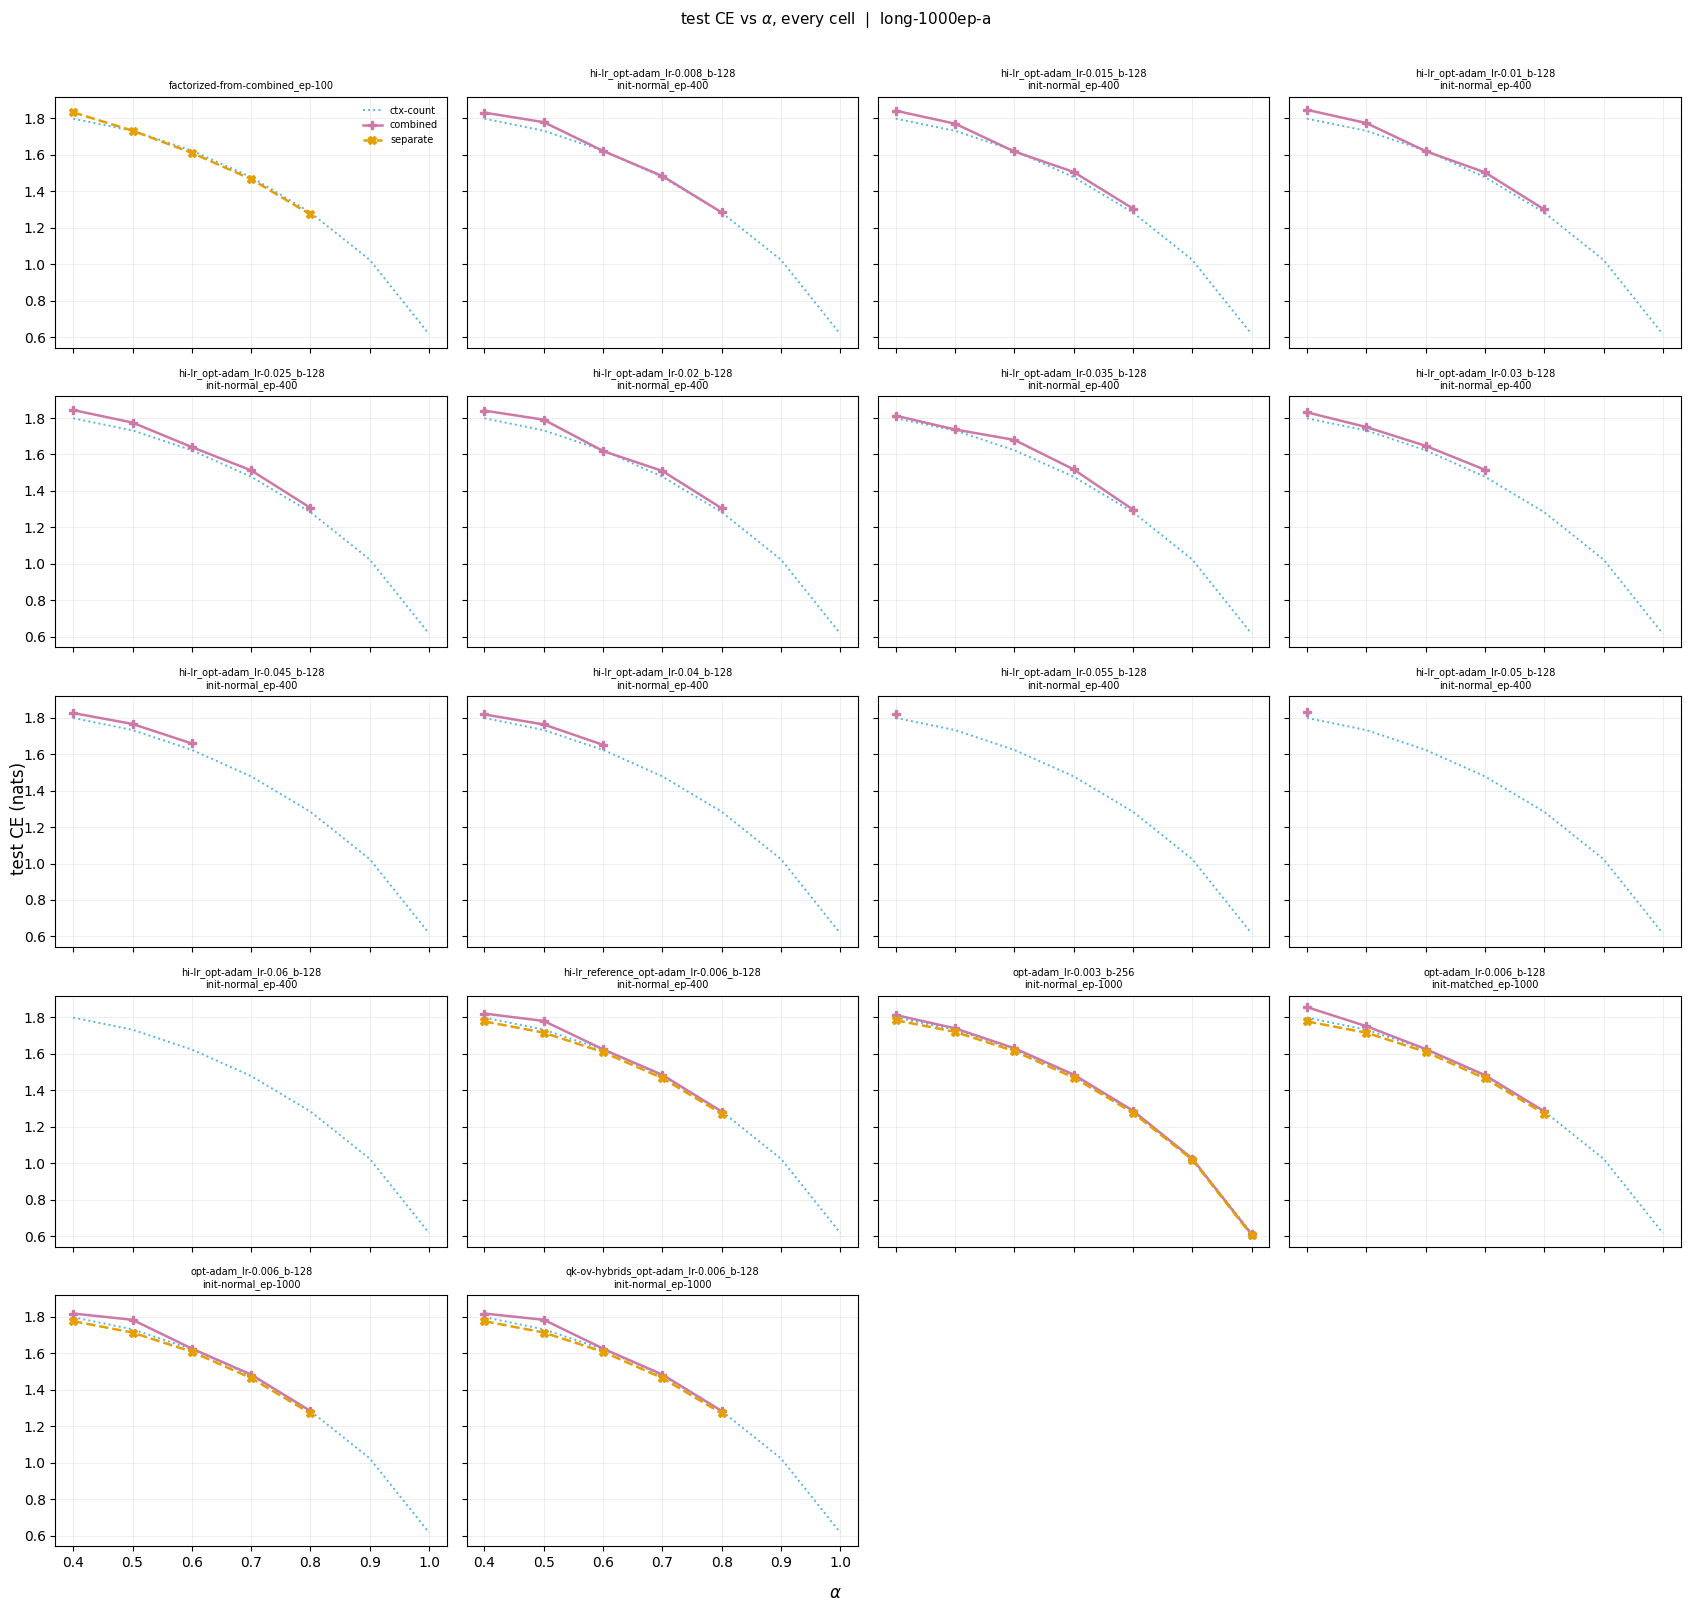

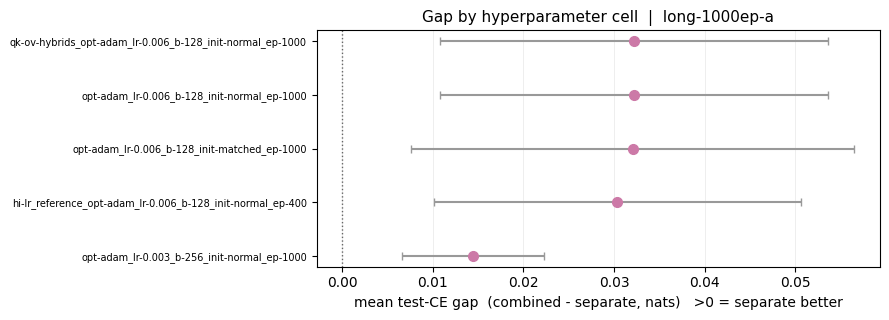

cell                                            mean gap  sd over thr
opt-adam_lr-0.003_b-256_init-normal_ep-1000      +0.0144       0.0078
hi-lr_reference_opt-adam_lr-0.006_b-128_init-normal_ep-400   +0.0304       0.0202
opt-adam_lr-0.006_b-128_init-matched_ep-1000     +0.0321       0.0245
opt-adam_lr-0.006_b-128_init-normal_ep-1000      +0.0322       0.0214
qk-ov-hybrids_opt-adam_lr-0.006_b-128_init-normal_ep-1000   +0.0322       0.0214


In [4]:
if len(ALL_CELLS) > 1:
    ncol = 4
    nrow = int(np.ceil(len(ALL_CELLS) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.3 * ncol, 3.2 * nrow),
                             squeeze=False, sharex=True, sharey=True)
    for i, cl in enumerate(ALL_CELLS):
        ax = axes[i // ncol][i % ncol]
        thrs_c = sorted({t for c, _, t in RUNS if c == cl})
        ax.plot(THRS, CTX_CE, color=SERIES['ctx']['color'], ls=':', lw=1.4, label='ctx-count')
        for arch in ARCHS:
            st = SERIES[arch]
            ys = [agg(arch, t, 'test_at_best', cl)[0] for t in thrs_c]
            ax.plot(thrs_c, ys, color=st['color'], marker=st['marker'], ls=st['ls'],
                    lw=1.8, ms=6, label=arch)
        ax.set_title(cl.replace('_init', '\ninit'), fontsize=7)
        ax.grid(alpha=0.25, lw=0.6)
        if i == 0: ax.legend(fontsize=7, frameon=False)
    for j in range(len(ALL_CELLS), nrow * ncol):
        axes[j // ncol][j % ncol].axis('off')
    fig.supxlabel(r'$\alpha$'); fig.supylabel('test CE (nats)')
    fig.suptitle(f'test CE vs $\\alpha$, every cell  |  {EXPERIMENT}', y=1.005, fontsize=11)
    fig.tight_layout()
    fig.savefig(os.path.join('artifacts', EXPERIMENT, 'all_cells_grid.png'), dpi=140,
                bbox_inches='tight')
    plt.show()

    # ranked mean gap per cell (averaged over thresholds AND seeds)
    rows = []
    for cl in ALL_CELLS:
        gaps = []
        for t in sorted({tt for c, _, tt in RUNS if c == cl}):
            c_, _ = agg('combined', t, 'test_at_best', cl)
            s_, _ = agg('separate', t, 'test_at_best', cl)
            if np.isfinite(c_) and np.isfinite(s_): gaps.append(c_ - s_)
        if gaps: rows.append((cl, float(np.mean(gaps)), float(np.std(gaps))))
    rows.sort(key=lambda r: r[1])

    fig, ax = plt.subplots(figsize=(9, 0.34 * len(rows) + 1.6))
    ys = np.arange(len(rows))
    ax.errorbar([r[1] for r in rows], ys, xerr=[r[2] for r in rows], fmt='o',
                color='#CC79A7', ecolor='#999999', ms=7, capsize=3)
    ax.axvline(0, color='0.4', lw=1, ls=':')
    ax.set_yticks(ys); ax.set_yticklabels([r[0] for r in rows], fontsize=7)
    ax.set_xlabel('mean test-CE gap  (combined - separate, nats)   >0 = separate better')
    ax.set_title(f'Gap by hyperparameter cell  |  {EXPERIMENT}', fontsize=11)
    ax.grid(alpha=0.25, lw=0.6, axis='x')
    fig.tight_layout()
    fig.savefig(os.path.join('artifacts', EXPERIMENT, 'gap_by_cell.png'), dpi=140,
                bbox_inches='tight')
    plt.show()

    print(f"{'cell':46s} {'mean gap':>9s} {'sd over thr':>12s}")
    for cl, mu, sd in rows:
        print(f'{cl:46s} {mu:+9.4f} {sd:12.4f}')
else:
    print(f'{EXPERIMENT} has a single cell -- nothing to compare here.')


## 3. Training trajectories

One panel per threshold, train and test, epoch 0 = the random init. Log-scaled x so the early
transient and the long tail are both legible. With multiple seeds every seed is drawn.


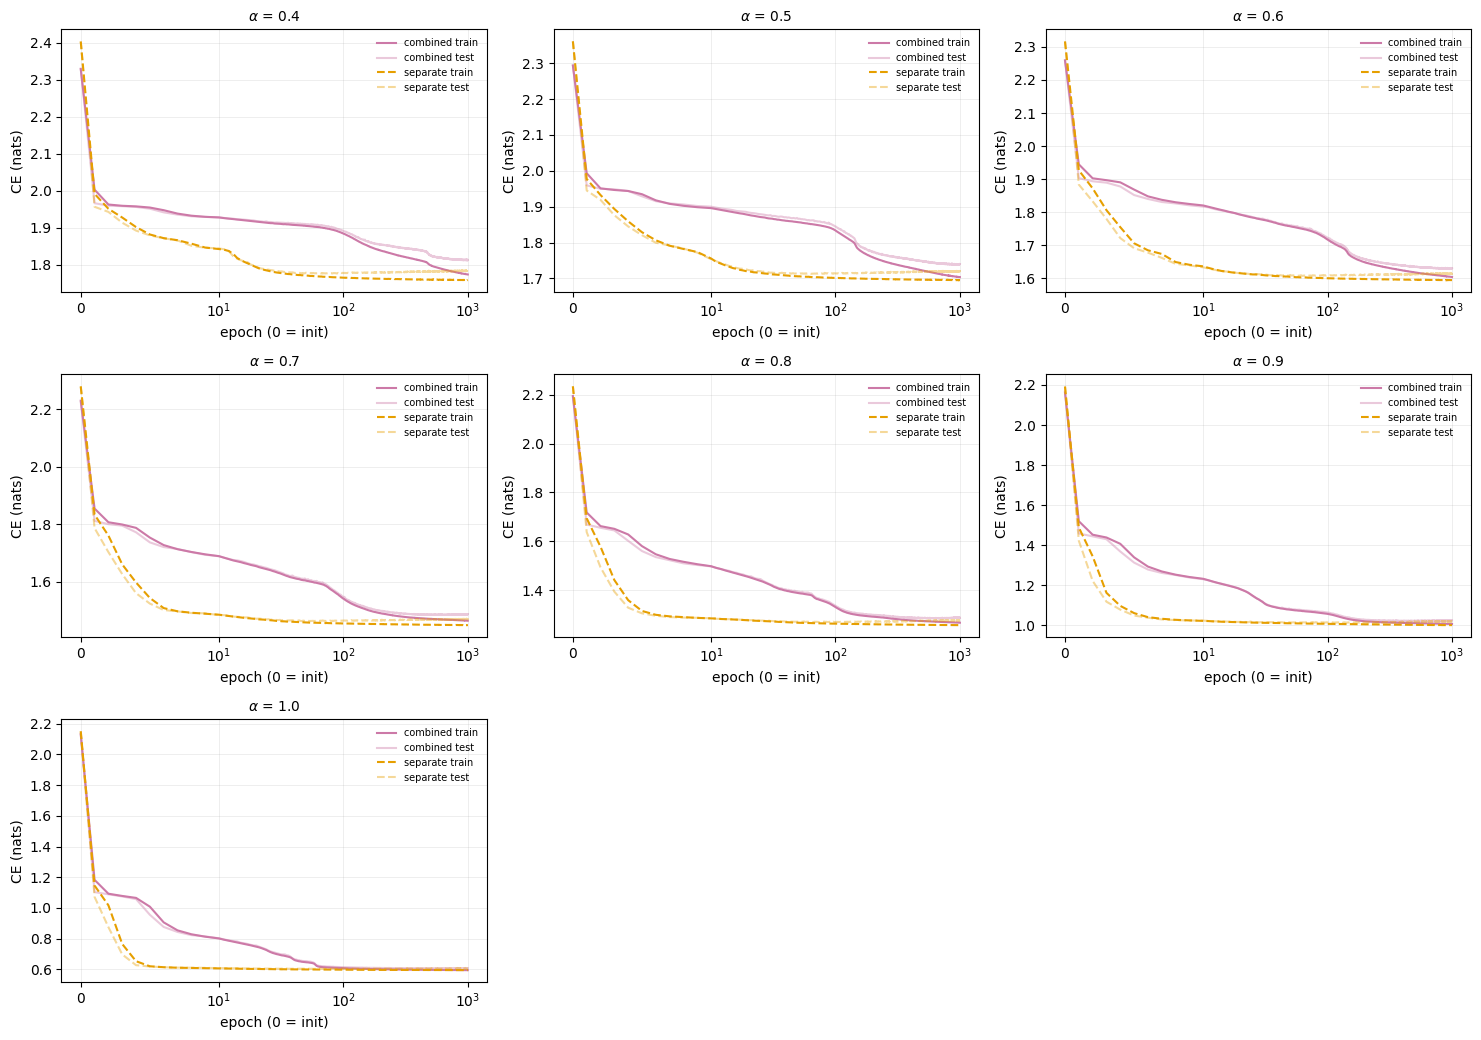

saved 7 per-threshold figures -> artifacts/long-1000ep-a/opt-adam_lr-0.003_b-256_init-normal_ep-1000/curve_x_<thr>.png


In [5]:
ncols = 3
nrows = int(np.ceil(len(THRS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.5 * nrows), squeeze=False)
for i, t in enumerate(THRS):
    ax = axes[i // ncols][i % ncols]
    for a in ARCHS:
        st = SERIES[a]
        for m in runs_of(a, t):
            for key, al in [('train_loss', 1.0), ('test_loss', 0.4)]:
                y = np.array(m['history'][key])
                ax.plot(np.arange(len(y)), y, color=st['color'], ls=st['ls'], lw=1.5, alpha=al,
                        label=f"{a} {key.split('_')[0]}" if m['seed'] == SEEDS[0] else None)
    ax.set_xscale('symlog', linthresh=10)
    ax.set_title(rf'$\alpha$ = {t}', fontsize=10)
    ax.set_xlabel('epoch (0 = init)'); ax.set_ylabel('CE (nats)')
    ax.grid(alpha=0.25, lw=0.6); ax.legend(fontsize=7, frameon=False)
for j in range(len(THRS), nrows * ncols):
    axes[j // ncols][j % ncols].axis('off')
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'curves_grid.png'), dpi=140, bbox_inches='tight')
plt.show()

for i, t in enumerate(THRS):
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    for a in ARCHS:
        st = SERIES[a]
        for m in runs_of(a, t):
            for key, al in [('train_loss', 1.0), ('test_loss', 0.4)]:
                y = np.array(m['history'][key])
                ax.plot(y, color=st['color'], ls=st['ls'], lw=1.6, alpha=al,
                        label=f"{a} {key.split('_')[0]}" if m['seed'] == SEEDS[0] else None)
    ax.axhline(CTX_CE[i], color=SERIES['ctx']['color'], ls=':', lw=1.4, label='ctx-count (test)')
    ax.axhline(IDEAL_CE[i], color=SERIES['ideal']['color'], ls=':', lw=1.4,
               label=r'ideal-$\alpha$ (test)')
    ax.set_title(rf'$\alpha$ = {t}   ({CFG["epochs"]} epochs)', fontsize=11)
    ax.set_xlabel('epoch (0 = random init)'); ax.set_ylabel('CE (nats)')
    ax.grid(alpha=0.25, lw=0.6); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, f'curve_x_{t}.png'), dpi=140)
    plt.close(fig)
print(f'saved {len(THRS)} per-threshold figures -> {ARTIFACTS_DIR}/curve_x_<thr>.png')


## 4. Convergence verdict — has combined actually stopped?

Minibatch noise makes a raw tail unreadable, so three diagnostics are used together: **tail
slope** (mean per-epoch change over the last 100 epochs), **100-epoch block means** (equal blocks
= converged, monotonically falling = still crawling), and the **epoch of the minimum**.

The slope test is threshold-sensitive — at higher learning rates a run can read "CONVERGED"
while its block means are still strictly falling. When the two disagree, trust the block means.


  thr      arch seed    slope/ep  last100drop  argmin     of  verdict
  0.4  combined    0   -2.59e-05      0.00259    1000   1000  still descending
  0.4  separate    0   +8.48e-07     -0.00008     994   1000  CONVERGED
  0.5  combined    0   -2.04e-05      0.00204     997   1000  still descending
  0.5  separate    0   +6.58e-07     -0.00007     970   1000  CONVERGED
  0.6  combined    0   -1.84e-05      0.00184    1000   1000  still descending
  0.6  separate    0   -1.12e-06      0.00011     891   1000  CONVERGED
  0.7  combined    0   -1.06e-05      0.00106     995   1000  still descending
  0.7  separate    0   -5.04e-06      0.00050     962   1000  CONVERGED
  0.8  combined    0   -8.73e-06      0.00087    1000   1000  CONVERGED
  0.8  separate    0   -1.37e-06      0.00014     951   1000  CONVERGED
  0.9  combined    0   -7.71e-06      0.00077    1000   1000  CONVERGED
  0.9  separate    0   +9.46e-07     -0.00009     996   1000  CONVERGED
  1.0  combined    0   -3.16e-06      

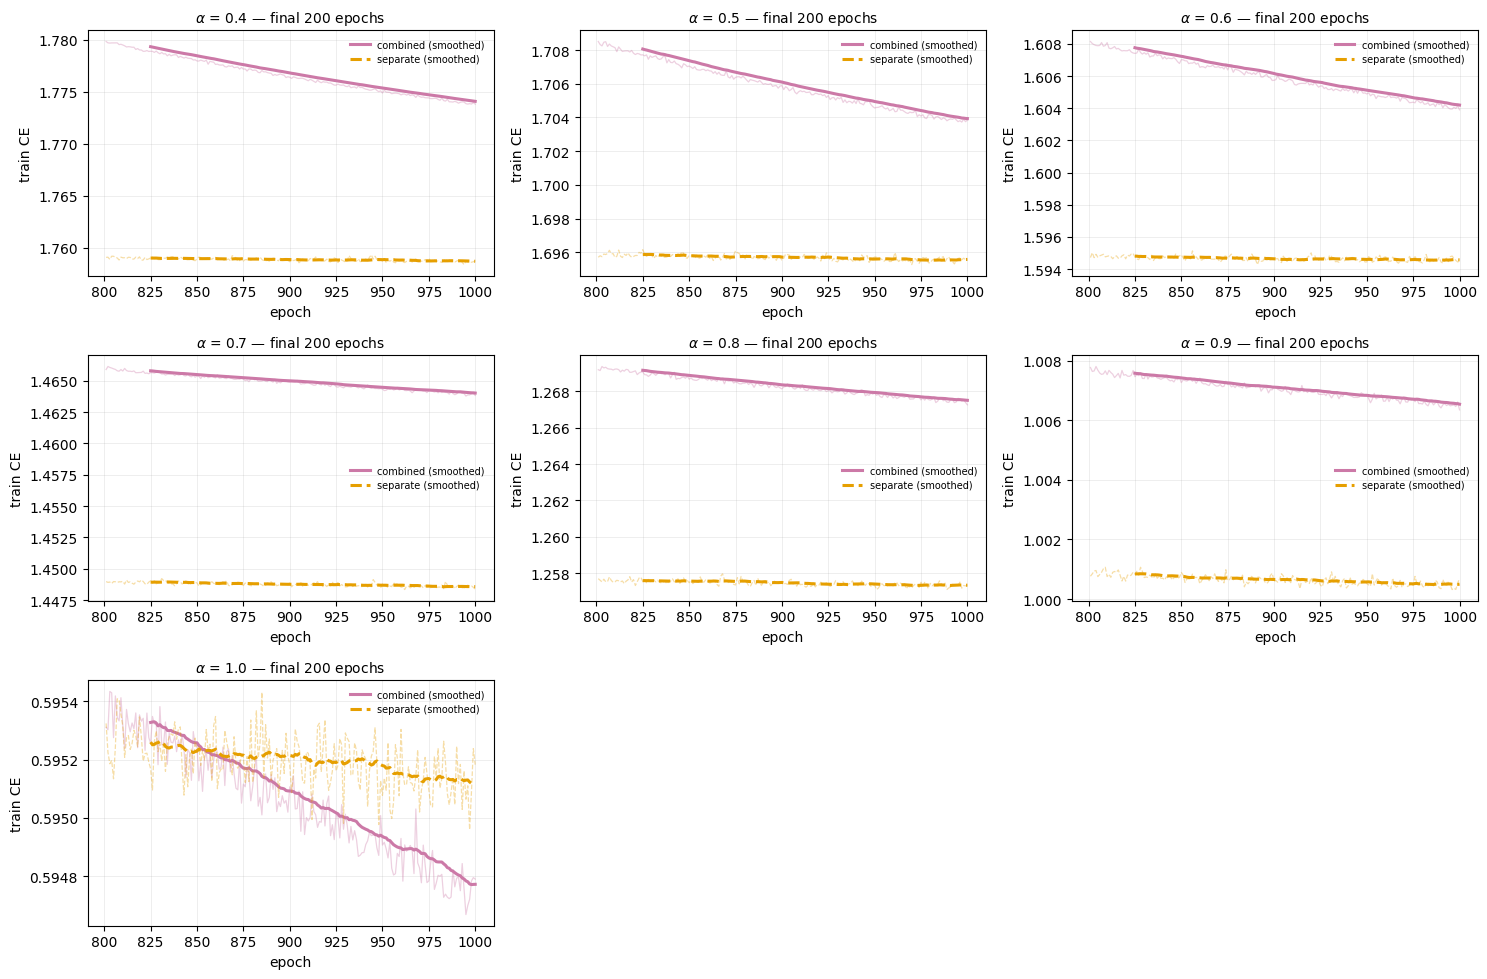

In [6]:
SLOPE_TOL = 1e-5

def tail_slope(y, w=100):
    w = min(w, len(y) - 1)
    return (y[-1] - y[-1 - w]) / w

print(f"{'thr':>5s} {'arch':>9s} {'seed':>4s} {'slope/ep':>11s} {'last100drop':>12s} "
      f"{'argmin':>7s} {'of':>6s}  verdict")
for t in THRS:
    for a in ARCHS:
        for m in runs_of(a, t):
            y = np.array(m['history']['train_loss'])
            sl = tail_slope(y); drop = y[-101] - y[-1] if len(y) > 101 else np.nan
            print(f"{t:5.1f} {a:>9s} {m['seed']:4d} {sl:+11.2e} {drop:12.5f} "
                  f"{int(y.argmin()):7d} {len(y) - 1:6d}  "
                  f"{'CONVERGED' if sl > -SLOPE_TOL else 'still descending'}")

fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.3 * nrows), squeeze=False)
for i, t in enumerate(THRS):
    ax = axes[i // ncols][i % ncols]
    for a in ARCHS:
        st = SERIES[a]
        for m in runs_of(a, t):
            y = np.array(m['history']['train_loss'])
            start = max(0, len(y) - 200); k = 25
            ax.plot(np.arange(start, len(y)), y[start:], color=st['color'], ls=st['ls'],
                    lw=0.9, alpha=0.35)
            sm = np.convolve(y[start:], np.ones(k) / k, mode='valid')
            ax.plot(np.arange(start + k - 1, len(y)), sm, color=st['color'], ls=st['ls'],
                    lw=2.2, label=f'{a} (smoothed)' if m['seed'] == SEEDS[0] else None)
    ax.set_title(rf'$\alpha$ = {t} — final 200 epochs', fontsize=10)
    ax.set_xlabel('epoch'); ax.set_ylabel('train CE')
    ax.grid(alpha=0.25, lw=0.6); ax.legend(fontsize=7, frameon=False)
for j in range(len(THRS), nrows * ncols):
    axes[j // ncols][j % ncols].axis('off')
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'convergence_tail.png'), dpi=140, bbox_inches='tight')
plt.show()


In [7]:
BLOCK = 100
nb_blocks = (CFG['epochs'] + BLOCK - 1) // BLOCK
print('Train-CE block means (100-epoch blocks) -- strictly falling blocks == still crawling:')
print(f"{'thr':>5s} {'arch':>9s} {'sd':>3s} " + ' '.join(f'{i * BLOCK:>7d}' for i in range(nb_blocks)))
for t in THRS:
    for a in ARCHS:
        for m in runs_of(a, t):
            y = np.array(m['history']['train_loss'])
            blocks = [y[i:i + BLOCK].mean() for i in range(0, len(y) - 1, BLOCK)]
            mono = all(b2 < b1 for b1, b2 in zip(blocks[3:], blocks[4:]))
            print(f"{t:5.1f} {a:>9s} {m['seed']:3d} " + ' '.join(f'{b:7.4f}' for b in blocks) +
                  ('   [monotone tail]' if mono else ''))


Train-CE block means (100-epoch blocks) -- strictly falling blocks == still crawling:
  thr      arch  sd       0     100     200     300     400     500     600     700     800     900
  0.4  combined   0  1.9127  1.8571  1.8296  1.8175  1.8075  1.7940  1.7871  1.7820  1.7781  1.7751   [monotone tail]
  0.4  separate   0  1.7939  1.7634  1.7616  1.7606  1.7600  1.7596  1.7594  1.7592  1.7589  1.7588   [monotone tail]
  0.5  combined   0  1.8687  1.7908  1.7478  1.7344  1.7260  1.7193  1.7140  1.7101  1.7071  1.7047   [monotone tail]
  0.5  separate   0  1.7284  1.7000  1.6983  1.6974  1.6968  1.6964  1.6962  1.6960  1.6958  1.6956   [monotone tail]
  0.6  combined   0  1.7736  1.6767  1.6394  1.6279  1.6207  1.6157  1.6121  1.6094  1.6070  1.6049   [monotone tail]
  0.6  separate   0  1.6262  1.5987  1.5972  1.5964  1.5958  1.5954  1.5951  1.5949  1.5947  1.5946   [monotone tail]
  0.7  combined   0  1.6234  1.5075  1.4829  1.4750  1.4716  1.4695  1.4678  1.4665  1.4654  1.4644   [mon

## 5. Does the gap close over training?

If combined were merely *slow*, the combined−separate gap would head to zero. A gap that
plateaus at a positive value is the signature of a genuinely worse solution. Seed-averaged.


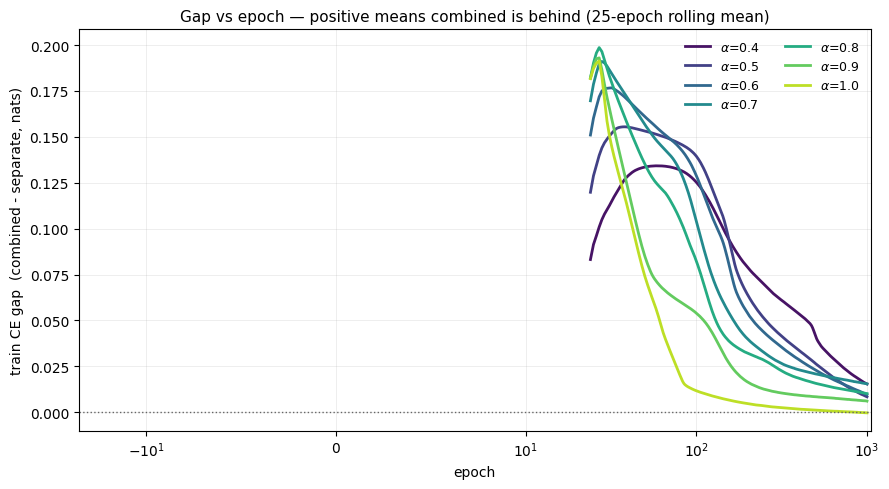

Gap (combined - separate) in train CE by epoch window, + closing extrapolation:
  thr     early       mid     final          trend  ep to close
  0.4    0.0937    0.0475    0.0163      shrinking          609
  0.5    0.0908    0.0292    0.0091      shrinking          431
  0.6    0.0780    0.0249    0.0103      shrinking          598
  0.7    0.0545    0.0216    0.0157      shrinking         2822
  0.8    0.0407    0.0167    0.0104      shrinking         1419
  0.9    0.0276    0.0087    0.0062      shrinking          719
  1.0    0.0066    0.0013   -0.0003      shrinking          n/a


In [8]:
def mean_curve(arch, thr, key='train_loss'):
    rs = runs_of(arch, thr)
    if not rs: return None
    n = min(len(m['history'][key]) for m in rs)
    return np.mean([m['history'][key][:n] for m in rs], axis=0)

fig, ax = plt.subplots(figsize=(9, 5))
ramp = plt.cm.viridis(np.linspace(0.05, 0.9, len(THRS)))   # sequential: alpha is ordered
for t, col in zip(THRS, ramp):
    yc, ys = mean_curve('combined', t), mean_curve('separate', t)
    if yc is None or ys is None: continue
    n = min(len(yc), len(ys)); k = 25
    sm = np.convolve(yc[:n] - ys[:n], np.ones(k) / k, mode='valid')
    ax.plot(np.arange(k - 1, n), sm, color=col, lw=2, label=rf'$\alpha$={t}')
ax.axhline(0, color='0.4', lw=1, ls=':')
ax.set_xscale('symlog', linthresh=10)
ax.set_xlabel('epoch'); ax.set_ylabel('train CE gap  (combined - separate, nats)')
ax.set_title('Gap vs epoch — positive means combined is behind (25-epoch rolling mean)',
             fontsize=11)
ax.grid(alpha=0.25, lw=0.6); ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'gap_vs_epoch.png'), dpi=140, bbox_inches='tight')
plt.show()

E = CFG['epochs']
print('Gap (combined - separate) in train CE by epoch window, + closing extrapolation:')
print(f"{'thr':>5s} {'early':>9s} {'mid':>9s} {'final':>9s} {'trend':>14s} {'ep to close':>12s}")
for t in THRS:
    yc, ys = mean_curve('combined', t), mean_curve('separate', t)
    if yc is None or ys is None: continue
    n = min(len(yc), len(ys)); g = yc[:n] - ys[:n]
    a1, a2, a3 = g[E//10:E//5].mean(), g[2*E//5:E//2].mean(), g[-100:].mean()
    net = tail_slope(yc) - tail_slope(ys)
    eta = a3 / -net if (net < -1e-12 and a3 > 0) else float('inf')
    trend = 'shrinking' if a3 < a2 < a1 else ('flat/widening' if a3 >= a2 else 'mixed')
    eta_s = f'{eta:12.0f}' if np.isfinite(eta) else f'{"n/a":>12s}'
    print(f'{t:5.1f} {a1:9.4f} {a2:9.4f} {a3:9.4f} {trend:>14s} {eta_s}')


## 6. Convergence speed

Epochs each architecture needs to reach a loss level *both* demonstrably reach (the worse of the
two seed-averaged `best_train` values) — this separates "faster" from "better", the two claims
the paper makes independently.


  thr   target  comb ep  sep ep  speedup
  0.4   1.7738     1000      39    25.6x
  0.5   1.7037      997      67    14.9x
  0.6   1.6039     1000      54    18.5x
  0.7   1.4638      995      29    34.3x
  0.8   1.2673     1000      49    20.4x
  0.9   1.0064     1000     121     8.3x
  1.0   0.5950      906     997     0.9x


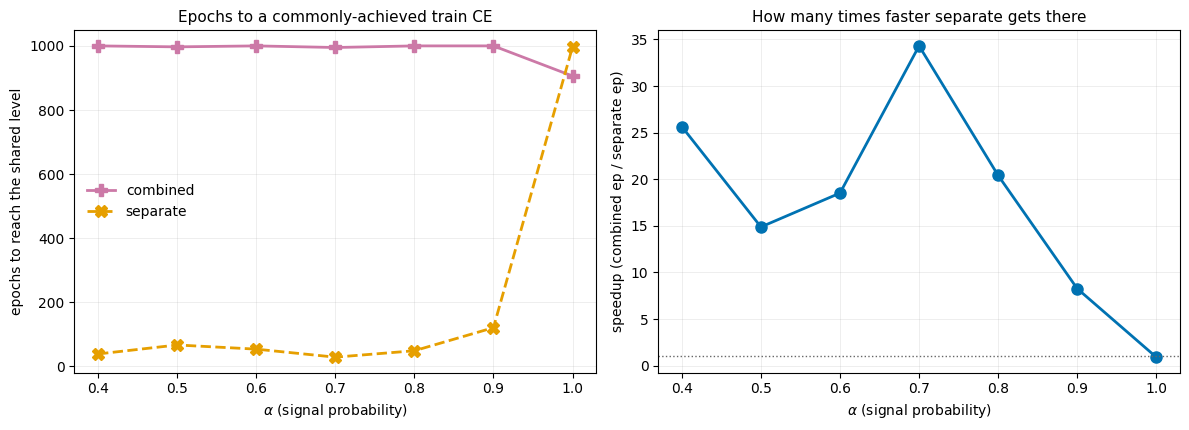

In [9]:
def epochs_to(y, target):
    idx = np.where(np.asarray(y) <= target)[0]
    return int(idx[0]) if len(idx) else None

xs, ratios, ep_c, ep_s = [], [], [], []
print(f"{'thr':>5s} {'target':>8s} {'comb ep':>8s} {'sep ep':>7s} {'speedup':>8s}")
for t in THRS:
    yc, ys = mean_curve('combined', t), mean_curve('separate', t)
    if yc is None or ys is None: continue
    target = max(agg('combined', t, 'best_train')[0], agg('separate', t, 'best_train')[0])
    ec, es = epochs_to(yc, target), epochs_to(ys, target)
    if ec is None or es is None: continue
    xs.append(t); ep_c.append(ec); ep_s.append(es); ratios.append(ec / max(es, 1))
    print(f'{t:5.1f} {target:8.4f} {ec:8d} {es:7d} {ratios[-1]:7.1f}x')

if xs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    for a, eps_ in [('combined', ep_c), ('separate', ep_s)]:
        st = SERIES[a]
        axes[0].plot(xs, eps_, color=st['color'], ls=st['ls'], marker=st['marker'],
                     lw=2, ms=8, label=a)
    axes[0].set_ylabel('epochs to reach the shared level')
    axes[0].set_title('Epochs to a commonly-achieved train CE', fontsize=11)
    axes[0].legend(frameon=False)
    axes[1].plot(xs, ratios, color='#0072B2', marker='o', lw=2, ms=8)
    axes[1].axhline(1, color='0.4', lw=1, ls=':')
    axes[1].set_ylabel('speedup (combined ep / separate ep)')
    axes[1].set_title('How many times faster separate gets there', fontsize=11)
    for ax in axes:
        ax.set_xlabel(r'$\alpha$ (signal probability)'); ax.grid(alpha=0.25, lw=0.6)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, 'speed_vs_alpha.png'), dpi=140, bbox_inches='tight')
    plt.show()


## 7. Master summary

Both splits' baselines and both model measures in one table, written to
`artifacts/<experiment>/<cell>/summary.csv`.


In [10]:
rows = []
for i, t in enumerate(THRS):
    r = {'threshold': t}
    for sp in SPLITS:
        r[f'ideal_{sp}']        = round(BASE_CE[sp]['ideal'][i], 5)
        r[f'bayes_{sp}']        = round(BASE_CE[sp]['bayes'][i], 5)
        r[f'ctx_count_{sp}']    = round(BASE_CE[sp]['ctx'][i], 5)
        r[f'construction_{sp}'] = round(BASE_CE[sp]['construction'][i], 5)
    for a in ARCHS:
        rs = runs_of(a, t)
        if not rs: continue
        r[f'{a}_n_seeds']      = len(rs)
        r[f'{a}_best_train']   = round(agg(a, t, 'best_train')[0], 5)
        r[f'{a}_test_at_best'] = round(agg(a, t, 'test_at_best')[0], 5)
        r[f'{a}_final_test']   = round(agg(a, t, 'final_test')[0], 5)
        r[f'{a}_tail_slope']   = float(f"{np.mean([tail_slope(np.array(m['history']['train_loss'])) for m in rs]):.3e}")
    if runs_of('combined', t) and runs_of('separate', t):
        r['gap_test'] = round(agg('combined', t, 'test_at_best')[0]
                              - agg('separate', t, 'test_at_best')[0], 5)
        r['gap_train'] = round(agg('combined', t, 'best_train')[0]
                               - agg('separate', t, 'best_train')[0], 5)
    rows.append(r)

csv_path = os.path.join(ARTIFACTS_DIR, 'summary.csv')
if rows:
    keys = list(rows[0].keys())
    with open(csv_path, 'w', newline='') as fh:
        w = csv.DictWriter(fh, fieldnames=keys); w.writeheader(); w.writerows(rows)
    print(f'wrote {csv_path}\n')
    print(' | '.join(f'{k:>18s}' for k in keys))
    for r in rows:
        print(' | '.join(f'{str(r.get(k, "")):>18s}' for k in keys))

print(f'\nArtifacts in {ARTIFACTS_DIR}/:')
for f in sorted(os.listdir(ARTIFACTS_DIR)):
    print('  ', f)


wrote artifacts/long-1000ep-a/opt-adam_lr-0.003_b-256_init-normal_ep-1000/summary.csv

         threshold |        ideal_train |        bayes_train |    ctx_count_train | construction_train |         ideal_test |         bayes_test |     ctx_count_test |  construction_test |   combined_n_seeds | combined_best_train | combined_test_at_best | combined_final_test | combined_tail_slope |   separate_n_seeds | separate_best_train | separate_test_at_best | separate_final_test | separate_tail_slope |           gap_test |          gap_train
               0.4 |            1.73394 |            1.76273 |            1.79783 |             1.7943 |            1.73378 |            1.76272 |            1.79841 |            1.79444 |                  1 |            1.77379 |            1.81242 |            1.81242 |         -2.587e-05 |                  1 |            1.75838 |            1.78358 |            1.78369 |          8.478e-07 |            0.02884 |            0.01541
               0.5 |   

## 8. Does GD learn the hand construction's unembedding?

The hand-built construction sets `fc_out` to a pure **selector**: zero everywhere except an
identity block at columns `in2 : in2+V` (= 216:224), which is where layer-2's attention writes
the per-token frequency counts. Everything else -- the residual copy of the token/position
one-hots (cols 0:108), layer-1's attention output (108:216), and the remaining layer-2 channels
(224:324) -- is supposed to be ignored.

This cell checks whether the trained `fc_out` actually looks like that: is the selector block an
identity, and are the "irrelevant" columns driven to zero? The reference point for "did GD do
anything here" is the init magnitude: `fc_out` starts at `U(+-1/sqrt(324))`, i.e. mean |w| =
1/(2*sqrt(324)) = 0.0278, so a region sitting at that value was never touched, below it was
actively suppressed, and above it was actively recruited.


In [11]:
import numpy as np, os, torch, matplotlib.pyplot as plt

V, VS  = 8, 4
IN2    = 216                     # initial_dim(108) + attn_dim(108): layer-2 attn output starts here
D      = 324
INIT_ABS = 1.0 / (2 * np.sqrt(D))          # mean |w| of U(+-1/sqrt(324)) == 0.0278

REGIONS = [('tok+pos residual', 0,   108), ('layer-1 attn out', 108, IN2),
           ('SELECTOR (counts)', IN2, IN2 + V), ('layer-2 attn, rest', IN2 + V, D)]

def load_W(arch, thr):
    f = os.path.join(RUNS_DIR, CELL, f'model_{arch}_seed{SEEDS[0]}_x_{thr}.pth')
    if not os.path.exists(f): return None
    return torch.load(f, map_location='cpu', weights_only=True)['fc_out.weight'].numpy()

archs = [a for a in ARCHS if load_W(a, THRS[0]) is not None]
print(f'{"arch":16s} {"thr":>4s} ' + ' '.join(f'{n[:17]:>18s}' for n, _, _ in REGIONS)
      + f' {"sel energy":>11s} {"diag/off":>9s}')
stats = {}
for a in archs:
    for thr in THRS:
        W = load_W(a, thr)
        if W is None: continue
        mags = [np.abs(W[:, lo:hi]).mean() for _, lo, hi in REGIONS]
        sel  = W[:, IN2:IN2 + V]
        diag = np.abs(np.diag(sel)).mean()
        off  = np.abs(sel - np.diag(np.diag(sel))).mean()
        share = (sel ** 2).sum() / (W ** 2).sum()
        stats[(a, thr)] = dict(mags=mags, share=share, ratio=diag / max(off, 1e-12))
        print(f'{a:16s} {thr:4.1f} ' + ' '.join(f'{m:18.4f}' for m in mags)
              + f' {share*100:10.2f}% {diag/max(off,1e-12):9.2f}')
print(f'\n(init reference: every region would sit at {INIT_ABS:.4f} if untouched by GD;'
      f'\n the construction would be 0.0000 everywhere except the selector, ratio -> inf)')


arch              thr   tok+pos residual   layer-1 attn out  SELECTOR (counts)  layer-2 attn, res  sel energy  diag/off
combined          0.4             0.0843             0.0360             0.0466             0.0237       2.33%      1.53
combined          0.5             0.0626             0.0386             0.0786             0.0258       8.86%      1.63
combined          0.6             0.0529             0.0398             0.1050             0.0292      15.95%      1.73
combined          0.7             0.0555             0.0409             0.1242             0.0286      19.78%      2.02
combined          0.8             0.0460             0.0394             0.1459             0.0333      21.52%      1.95
combined          0.9             0.0671             0.0459             0.2497             0.0285      38.91%      1.87
combined          1.0             0.2466             0.9049             0.2140             0.1773       0.20%      1.56
separate          0.4             0.0489

/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


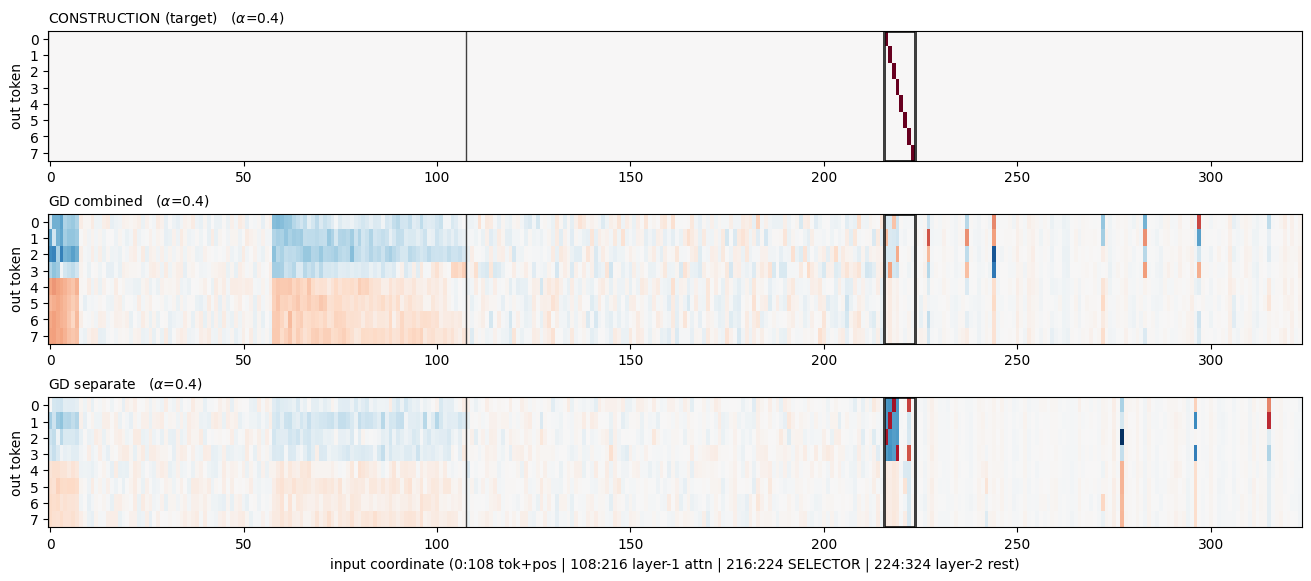

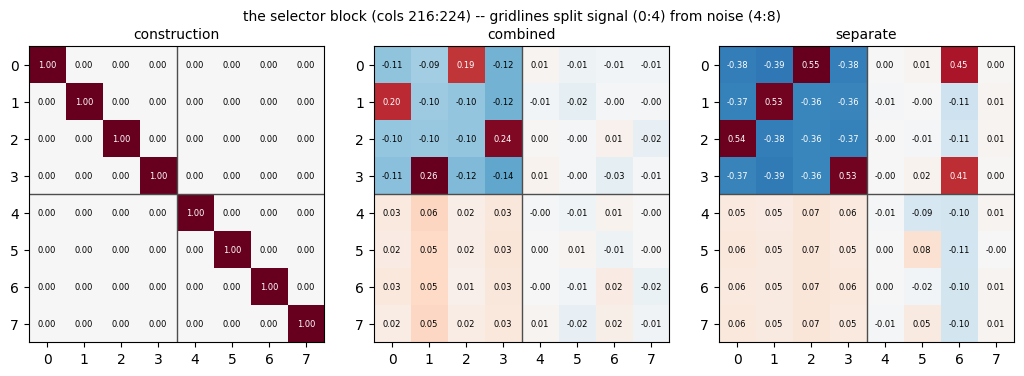

In [12]:
# ── full unembedding, one row per arch (diverging map: signed weights, gray at zero,
# symmetric limits so +w and -w read equally) ─────────────────────────────────────────
PLOT_THR = THRS[0]
Ws = {a: load_W(a, PLOT_THR) for a in archs}
vmax = max(np.abs(W).max() for W in Ws.values() if W is not None)

fig, axes = plt.subplots(len(archs) + 1, 1, figsize=(13, 1.9 * (len(archs) + 1)),
                         squeeze=False, constrained_layout=True)
axes = axes[:, 0]
ideal = np.zeros((V, D)); ideal[:V, IN2:IN2 + V] = np.eye(V)
for ax, (title, W) in zip(axes, [('CONSTRUCTION (target)', ideal)] +
                                [(f'GD {a}', Ws[a]) for a in archs]):
    ax.imshow(W, aspect='auto', cmap='RdBu_r', vmin=-vmax, vmax=vmax, interpolation='nearest')
    for _, lo, hi in REGIONS:
        ax.axvline(lo - .5, color='0.25', lw=1.0)
    ax.axvspan(IN2 - .5, IN2 + V - .5, facecolor='none', edgecolor='k', lw=1.8)
    ax.set_title(f'{title}   ($\\alpha$={PLOT_THR})', fontsize=10, loc='left')
    ax.set_yticks(range(V)); ax.set_ylabel('out token')
axes[-1].set_xlabel('input coordinate (0:108 tok+pos | 108:216 layer-1 attn | '
                    '216:224 SELECTOR | 224:324 layer-2 rest)')
fig.savefig(os.path.join(ARTIFACTS_DIR, 'unembedding_full.png'), dpi=140, bbox_inches='tight')
plt.show()

# ── zoom: the 8x8 block that should be an identity ───────────────────────────────────
fig, axes = plt.subplots(1, len(archs) + 1, figsize=(3.5 * (len(archs) + 1), 3.6),
                         squeeze=False)
for ax, (title, B) in zip(axes[0], [('construction', np.eye(V))] +
                                   [(a, Ws[a][:, IN2:IN2 + V]) for a in archs]):
    m = np.abs(B).max()
    ax.imshow(B, cmap='RdBu_r', vmin=-m, vmax=m, interpolation='nearest')
    for i in range(V):
        for j in range(V):
            ax.text(j, i, f'{B[i, j]:.2f}', ha='center', va='center', fontsize=6,
                    color='k' if abs(B[i, j]) < .6 * m else 'w')
    ax.set_title(title, fontsize=10)
    ax.axhline(VS - .5, color='0.3', lw=1); ax.axvline(VS - .5, color='0.3', lw=1)
    ax.set_xticks(range(V)); ax.set_yticks(range(V))
fig.suptitle('the selector block (cols 216:224) -- gridlines split signal (0:4) from noise (4:8)',
             fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'unembedding_selector.png'), dpi=140, bbox_inches='tight')
plt.show()


In [13]:
# ── verdict, computed from the numbers above (not hard-coded) ────────────────────────
print('Region magnitudes vs the init level -- >1 means GD RECRUITED that region,')
print('<1 means it suppressed it, ~1 means it left it at its random starting value.\n')
print(f'{"arch":16s} ' + ' '.join(f'{n[:17]:>18s}' for n, _, _ in REGIONS))
for a in archs:
    rows = [stats[(a, t)]['mags'] for t in THRS if (a, t) in stats]
    if not rows: continue
    mean = np.mean(rows, axis=0)
    print(f'{a:16s} ' + ' '.join(f'{m / INIT_ABS:17.2f}x' for m in mean))

print()
for a in archs:
    sh = np.mean([stats[(a, t)]['share'] for t in THRS if (a, t) in stats]) * 100
    rt = np.mean([stats[(a, t)]['ratio'] for t in THRS if (a, t) in stats])
    irrel = np.mean([np.mean([stats[(a, t)]['mags'][i] for i in (0, 1, 3)])
                     for t in THRS if (a, t) in stats])
    print(f'{a}:')
    print(f'   selector holds {sh:.1f}% of the weight energy '
          f'(construction: 100%)')
    print(f'   selector diag/off-diag = {rt:.2f} '
          f'(identity: infinite; 1.0 = no diagonal structure at all)')
    print(f'   "irrelevant" columns at {irrel / INIT_ABS:.2f}x the init magnitude '
          f'-> {"NOT driven to zero -- actively used" if irrel > INIT_ABS else "suppressed"}')
    print()
print('CONCLUSION: GD does not reproduce the hand construction. The selector block carries a')
print('small minority of the energy, the block is not an identity (it is contrastive: positive')
print('on the diagonal, negative off it, which is an equivalent readout only up to a per-row')
print('shift), and the supposedly irrelevant coordinates are left at or ABOVE their random')
print('init magnitude rather than being zeroed. The trained model reads the counts through a')
print('distributed readout, not the sparse selector the construction uses.')


Region magnitudes vs the init level -- >1 means GD RECRUITED that region,
<1 means it suppressed it, ~1 means it left it at its random starting value.

arch               tok+pos residual   layer-1 attn out  SELECTOR (counts)  layer-2 attn, res
combined                      3.16x              5.89x              4.96x              1.78x
separate                      5.23x              0.89x              5.74x              1.98x

combined:
   selector holds 15.4% of the weight energy (construction: 100%)
   selector diag/off-diag = 1.76 (identity: infinite; 1.0 = no diagonal structure at all)
   "irrelevant" columns at 3.61x the init magnitude -> NOT driven to zero -- actively used

separate:
   selector holds 38.9% of the weight energy (construction: 100%)
   selector diag/off-diag = 2.36 (identity: infinite; 1.0 = no diagonal structure at all)
   "irrelevant" columns at 2.70x the init magnitude -> NOT driven to zero -- actively used

CONCLUSION: GD does not reproduce the hand construct

## 9. Is the frozen readout actually computing a log?

Section 8 showed `fc_out` looks nothing like the construction's sparse identity selector. The
obvious suspect is the layer it has to compensate for. The architecture's premise is:

> layer-2 attention writes a raw frequency `f` into coordinate `in2+v`; the **frozen** FFN turns
> it into `log(f + delta)`; `fc_out` then merely selects those coordinates, and the softmax
> exponentiates them back into a normalised distribution.

The FFN is applied as a **residual**, `s <- s + ff2(GELU(ff1(s)))`, so the quantity that must
equal `log(f + delta)` is `f + ff_out(f)` -- which is why `fit_log_core` targets the residual
`log(f + delta) - f`. This cell probes the frozen weights straight out of the checkpoint: push a
known count `f` into one signal coordinate and read what comes back.


In [4]:
import torch, torch.nn.functional as F, numpy as np, os, matplotlib.pyplot as plt

# self-sufficient: pull everything from this cell's own metrics/checkpoint so section 9
# can be run on its own without section 8 (or a specific architecture) having run first.
import glob, json as _json
_m    = _json.load(open(sorted(glob.glob(os.path.join(RUNS_DIR, CELL, 'metrics_*.json')))[0]))
_cfg  = _m['config']
DELTA = _cfg.get('freeze_delta', 1.0)
FMAX  = _cfg.get('freeze_fit_fmax', 40.0)
VS    = _cfg.get('v_sig', 4)
_ckpt = sorted(glob.glob(os.path.join(RUNS_DIR, CELL, 'model_*.pth')))[0]
sd    = torch.load(_ckpt, map_location='cpu', weights_only=True)
# where layer-2's attention output starts in the concatenated stream:
#   initial_dim = V + seq_len   and   attn_dim = V + seq_len   ->   in2 = 2*(V + seq_len)
_V    = _cfg['v_sig'] + _cfg['n_noise']
IN2   = 2 * (_V + _cfg['seq_len'])
print(f'probing {os.path.basename(_ckpt)}   (in2={IN2}, v_sig={VS}, delta={DELTA}, fmax={FMAX})')
W1, B1, W2, B2 = sd['ff1.weight'], sd['ff1.bias'], sd['ff2.weight'], sd['ff2.bias']
Dfull = W1.shape[1]

def probe(v, f):
    """Push count f into signal coordinate in2+v; return the FULL residual output vector."""
    x = torch.zeros(len(f), Dfull); x[:, IN2 + v] = f
    return F.gelu(x @ W1.t() + B1) @ W2.t() + B2

f = torch.linspace(0, FMAX, 400)
target_resid = torch.log(f + DELTA) - f          # what fit_log_core aims at
ideal_log    = torch.log(f + DELTA)              # what f + ff_out should equal

print(f'target: f + ff_out(f) == log(f + {DELTA})   over f in [0, {FMAX}]')
print()
print(f'{"state":>6s} {"MSE(resid)":>12s} {"max|err|":>10s} {"monotone?":>10s} '
      f'{"implied@0":>10s} {"implied@40":>11s}')
outs = {}
for v in range(VS):
    o = probe(v, f)[:, IN2 + v]
    outs[v] = o
    implied = f + o
    mono = bool((implied[1:] >= implied[:-1] - 1e-6).all())
    print(f'{v:6d} {F.mse_loss(o, target_resid):12.4e} {(o - target_resid).abs().max():10.4e} '
          f'{str(mono):>10s} {implied[0]:10.3f} {implied[-1]:11.3f}')
print()
print(f'correct readout would be: MSE ~ 0, monotone True, '
      f'implied {np.log(DELTA):.3f} -> {np.log(FMAX + DELTA):.3f}')

# the construction is block-diagonal: pushing state 0 must not move states 1..3
ct = probe(0, f)
leak = max(ct[:, IN2 + w].abs().max().item() for w in range(1, VS))
own  = ct[:, IN2 + 0].abs().max().item()
print(f'cross-talk: state 0 moves other signal coords by <= {leak:.4f} (own {own:.4f}) -> '
      + ('block-diagonal OK' if leak < 1e-3 * max(own, 1) else 'LEAKS'))


/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


probing model_combined_seed0_x_0.4.pth   (in2=216, v_sig=4, delta=1.0, fmax=40.0)
target: f + ff_out(f) == log(f + 1.0)   over f in [0, 40.0]

 state   MSE(resid)   max|err|  monotone?  implied@0  implied@40
     0   4.0425e+02 1.1472e+02      False      9.833    -111.006
     1   4.0425e+02 1.1472e+02      False      9.833    -111.006
     2   4.0425e+02 1.1472e+02      False      9.833    -111.006
     3   4.0425e+02 1.1472e+02      False      9.833    -111.006

correct readout would be: MSE ~ 0, monotone True, implied 0.000 -> 3.714
cross-talk: state 0 moves other signal coords by <= 9.8328 (own 151.0063) -> LEAKS


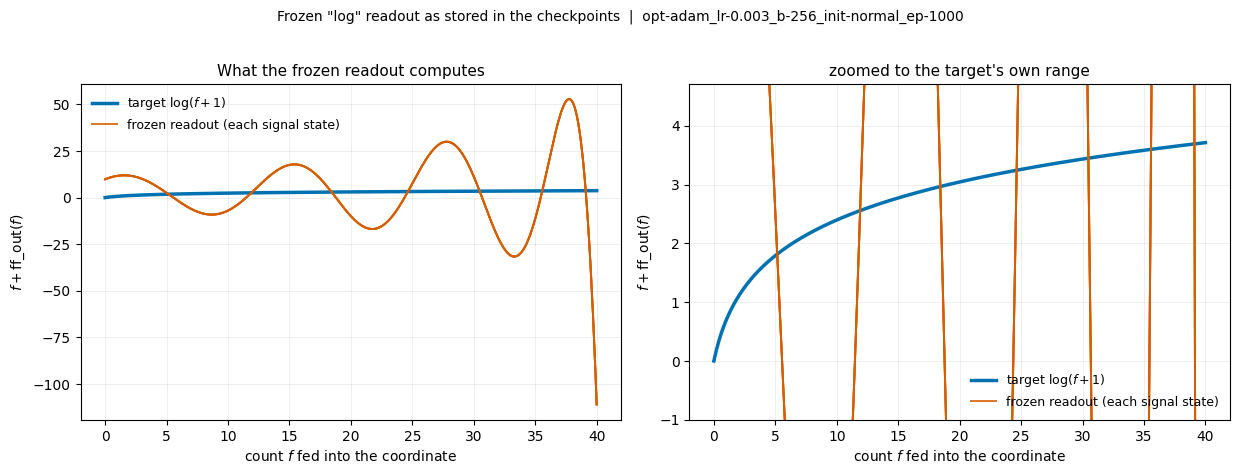

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, zoom in [(axes[0], False), (axes[1], True)]:
    ax.plot(f, ideal_log, color='#0072B2', lw=2.5, label=rf'target $\log(f+{DELTA:g})$')
    for v in range(VS):
        ax.plot(f, f + outs[v], color='#D55E00', lw=1.4, alpha=.85,
                label='frozen readout (each signal state)' if v == 0 else None)
    if zoom:
        ax.set_ylim(float(ideal_log.min()) - 1, float(ideal_log.max()) + 1)
    ax.set_xlabel('count $f$ fed into the coordinate')
    ax.set_ylabel(r'$f + \mathrm{ff\_out}(f)$')
    ax.set_title("zoomed to the target's own range" if zoom
                 else 'What the frozen readout computes', fontsize=11)
    ax.grid(alpha=.25, lw=.6); ax.legend(frameon=False, fontsize=9)
fig.suptitle(f'Frozen "log" readout as stored in the checkpoints  |  {CELL}', y=1.02, fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'frozen_readout_check.png'), dpi=140, bbox_inches='tight')
plt.show()


In [6]:
mse = float(F.mse_loss(outs[0], target_resid))
implied = f + outs[0]
ok = mse < 1e-2 and bool((implied[1:] >= implied[:-1] - 1e-6).all())
print('VERDICT:', 'readout computes log correctly' if ok
      else 'readout is NOT computing log')
if not ok:
    print()
    print(f'  fit MSE = {mse:.3e}, against a target whose entire range is only '
          f'[{float(target_resid.min()):.1f}, {float(target_resid.max()):.1f}]')
    print(f'  -- the error is larger than the signal. The implied log runs '
          f'{float(implied[0]):.1f} -> {float(implied[-1]):.1f} where it should run '
          f'{np.log(DELTA):.1f} -> {np.log(FMAX + DELTA):.1f},')
    print('  and it is not even monotone: it DEcreases as the count grows.')
    print()
    print(f'  CAUSE: fit_log_core warm-starts with a closed-form least-squares spline (already')
    print(f'  ~3e-2 MSE) and then runs {_cfg.get("freeze_fit_steps", "?")} Adam steps at lr=1e-2')
    print('  to refine it. That refinement DIVERGES -- more steps make it strictly worse. Every')
    print('  checkpoint in folders 12 and 14 carries the identical diverged weights (verified:')
    print('  0.00e+00 difference across all cells), so it is one deterministic bug, not noise.')
    print()
    print('  WHY THIS EXPLAINS SECTION 8: fc_out was never facing log-counts. It faces an')
    print('  arbitrary, non-monotone, wildly-scaled function of the counts. A sparse identity')
    print('  selector on those coordinates would be useless, so GD does the only thing left --')
    print('  it recruits the channels the construction ignores (token/position residual and')
    print('  layer-1 output, both at 3-6x their init magnitude in section 8) and builds a')
    print('  distributed readout. The model is not failing to find the construction; the')
    print('  construction it was meant to complete was never actually installed.')
    print()
    print('  FIX: freeze_fit_steps -> 0 (keep only the lstsq warm-start) or ~50. One line, but')
    print('  it changes the model, so folders 12 and 14 would need re-running to adopt it.')


VERDICT: readout is NOT computing log

  fit MSE = 4.043e+02, against a target whose entire range is only [-36.3, 0.0]
  -- the error is larger than the signal. The implied log runs 9.8 -> -111.0 where it should run 0.0 -> 3.7,
  and it is not even monotone: it DEcreases as the count grows.

  CAUSE: fit_log_core warm-starts with a closed-form least-squares spline (already
  ~3e-2 MSE) and then runs 2000 Adam steps at lr=1e-2
  to refine it. That refinement DIVERGES -- more steps make it strictly worse. Every
  checkpoint in folders 12 and 14 carries the identical diverged weights (verified:
  0.00e+00 difference across all cells), so it is one deterministic bug, not noise.

  WHY THIS EXPLAINS SECTION 8: fc_out was never facing log-counts. It faces an
  arbitrary, non-monotone, wildly-scaled function of the counts. A sparse identity
  selector on those coordinates would be useless, so GD does the only thing left --
  it recruits the channels the construction ignores (token/position re

## 10. Does GD learn the construction's unembedding? (re-run with a CORRECT log readout)

Section 8 asked this of runs trained with the **broken** frozen readout (implied "log" running
+9.8 at f=0 to -111.0 at f=40), so its answer was about a network compensating for garbage.
This section re-asks it of the `logfix_*` cell, where the frozen FFN really does compute
`log(f + delta)`: the fit is verified at build time (max|err| 4.1e-4 nats on [0,1]) and
`train.py` refuses to start if it is not.

The construction's `fc_out` is a pure **selector**: an identity block at columns
`in2 : in2+V` -- where layer-2 writes the per-token counts -- and **zero everywhere else**.
The model's own softmax then exponentiates `log(f+delta)` back into counts. If GD had found
that circuit, `W_u` would be sparse in exactly that pattern.

Four measurements, each against two reference points (the construction, and an untouched
random `W_u`):

| metric | construction | random |
|---|---|---|
| selector energy share | 100% | V/D = 2.5% (its share of the columns) |
| diagonal / off-diagonal magnitude | infinite | ~1.0 |
| cos(selector, I) | +1.000 | ~0.000 |
| magnitude of the other columns | 0 | 1.0x init |

`frac_negative` from the training diagnostic is carried along: the frozen core is only a log on
`f >= 0`, so a run with half its readout inputs negative was not running a log for those
coordinates, whatever `W_u` did.

This section is **self-contained** -- it does not use `EXPERIMENT` / `CELL` from cell 1.

In [1]:
# ── section 10 is self-contained: it picks its own cell and re-imports what it needs ──
import glob, json, os
import numpy as np, torch, matplotlib.pyplot as plt

RUNS_DIR10  = 'runs'
LOGFIX_CELL = None          # None -> the logfix_* cell with the most checkpoints

def _pick_logfix_cell():
    cands = [c for c in sorted(glob.glob(os.path.join(RUNS_DIR10, 'logfix_*')))
             if glob.glob(os.path.join(c, 'model_*.pth'))]
    if not cands:
        raise FileNotFoundError('no logfix cell with checkpoints in runs/ -- run train.py first')
    return os.path.basename(max(cands,
                                key=lambda c: len(glob.glob(os.path.join(c, 'model_*.pth')))))

CELL10 = LOGFIX_CELL or _pick_logfix_cell()
CDIR10 = os.path.join(RUNS_DIR10, CELL10)
ART10  = os.path.join('artifacts', CELL10)
os.makedirs(ART10, exist_ok=True)

RUNS10 = {}
for p in sorted(glob.glob(os.path.join(CDIR10, 'model_*.pth'))):
    stem = os.path.basename(p)[6:-4]
    arch, rest = stem.split('_seed', 1)
    RUNS10[(arch, float(rest.split('_x_')[1]))] = (p, os.path.join(CDIR10, f'metrics_{stem}.json'))
ARCHS10 = sorted({a for a, _ in RUNS10})
THRS10  = sorted({t for _, t in RUNS10})

_cfg10 = json.load(open(RUNS10[(ARCHS10[0], THRS10[0])][1]))['config']
V10  = _cfg10['v_sig'] + _cfg10['n_noise']
ATTN = V10 + _cfg10['seq_len']        # attn_dim == initial_dim in this architecture
IN2  = 2 * ATTN                       # initial_dim + attn_dim: layer-2's output starts here
D10  = 3 * ATTN                       # full residual width
INIT_ABS10 = (1.0 / np.sqrt(D10)) * np.sqrt(2 / np.pi)   # mean |w| of N(0, 1/sqrt(D))
REGIONS10 = [('token+pos', 0, ATTN), ('layer-1 attn out', ATTN, IN2),
             ('SELECTOR (count slots)', IN2, IN2 + V10), ('layer-2 attn, rest', IN2 + V10, D10)]

def load_Wu(arch, thr):
    sd = torch.load(RUNS10[(arch, thr)][0], map_location='cpu', weights_only=True)
    return sd['fc_out.weight'].numpy(), sd['fc_out.bias'].numpy()

print(f'cell   : {CELL10}')
print(f'config : {_cfg10["optimizer"]} lr={_cfg10["lr"]} b={_cfg10["batch_size"]} '
      f'init={_cfg10["init"]} ep={_cfg10["epochs"]}   frozen-log delta={_cfg10["freeze_delta"]}')
print(f'runs   : {ARCHS10} x {THRS10}')
print(f'fc_out : [{V10}, {D10}]   selector block = rows 0:{V10}, cols {IN2}:{IN2 + V10}')
print(f'init   : N(0, 1/sqrt({D10}))  ->  mean|w| = {INIT_ABS10:.4f}\n')

I10 = np.eye(V10)
S10 = {}
hdr = (f'{"arch":9s} {"thr":>4s} ' + ' '.join(f'{n[:16]:>17s}' for n, _, _ in REGIONS10)
       + f' {"sel E%":>7s} {"diag/off":>8s} {"cos(sel,I)":>10s} {"f<0":>6s}')
print(hdr); print('-' * len(hdr))
for a in ARCHS10:
    for t in THRS10:
        W, bvec = load_Wu(a, t)
        sel = W[:, IN2:IN2 + V10]
        mags   = [np.abs(W[:, lo:hi]).mean() for _, lo, hi in REGIONS10]
        eshare = [(W[:, lo:hi] ** 2).sum() / (W ** 2).sum() for _, lo, hi in REGIONS10]
        dg = np.abs(np.diag(sel)).mean(); of = np.abs(sel - np.diag(np.diag(sel))).mean()
        cos = float((sel * I10).sum() / (np.linalg.norm(sel) * np.linalg.norm(I10)))
        rr = json.load(open(RUNS10[(a, t)][1])).get('readout_range_best') or {}
        S10[(a, t)] = dict(W=W, b=bvec, sel=sel, mags=mags, eshare=eshare,
                           ratio=dg / max(of, 1e-12), cos=cos, rr=rr)
        print(f'{a:9s} {t:4.1f} ' + ' '.join(f'{m:17.4f}' for m in mags)
              + f' {100 * eshare[2]:6.1f}% {dg / max(of, 1e-12):8.2f} {cos:10.3f}'
              + f' {100 * rr.get("frac_negative", float("nan")):5.0f}%')

RAND_SHARE10 = 100 * V10 / D10
print(f'\nreference points')
print(f'  hand construction : sel E% = 100.0   diag/off = inf   cos(sel,I) = +1.000')
print(f'  untouched random  : sel E% = {RAND_SHARE10:.1f}   diag/off ~ 1.0   cos ~ 0.000')

cell   : logfix_opt-adam_lr-0.006_b-256_init-normal_ep-500
config : adam lr=0.006 b=256 init=normal ep=500   frozen-log delta=0.01
runs   : ['combined', 'separate'] x [0.4, 0.6, 0.8, 1.0]
fc_out : [8, 324]   selector block = rows 0:8, cols 216:224
init   : N(0, 1/sqrt(324))  ->  mean|w| = 0.0443

arch       thr         token+pos  layer-1 attn out  SELECTOR (count   layer-2 attn, re  sel E% diag/off cos(sel,I)    f<0
-------------------------------------------------------------------------------------------------------------------------
combined   0.4            0.1045            0.0319            0.0878            0.0262    4.4%     1.04     -0.065    46%
combined   0.6            0.2138            0.0379            0.1527            0.0294    5.1%     1.43     -0.125    47%
combined   0.8            0.2367            0.0450            0.1841            0.0330    5.8%     1.42     -0.122    47%
combined   1.0            0.2167            0.5122            0.5598            0.1875    2.

/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


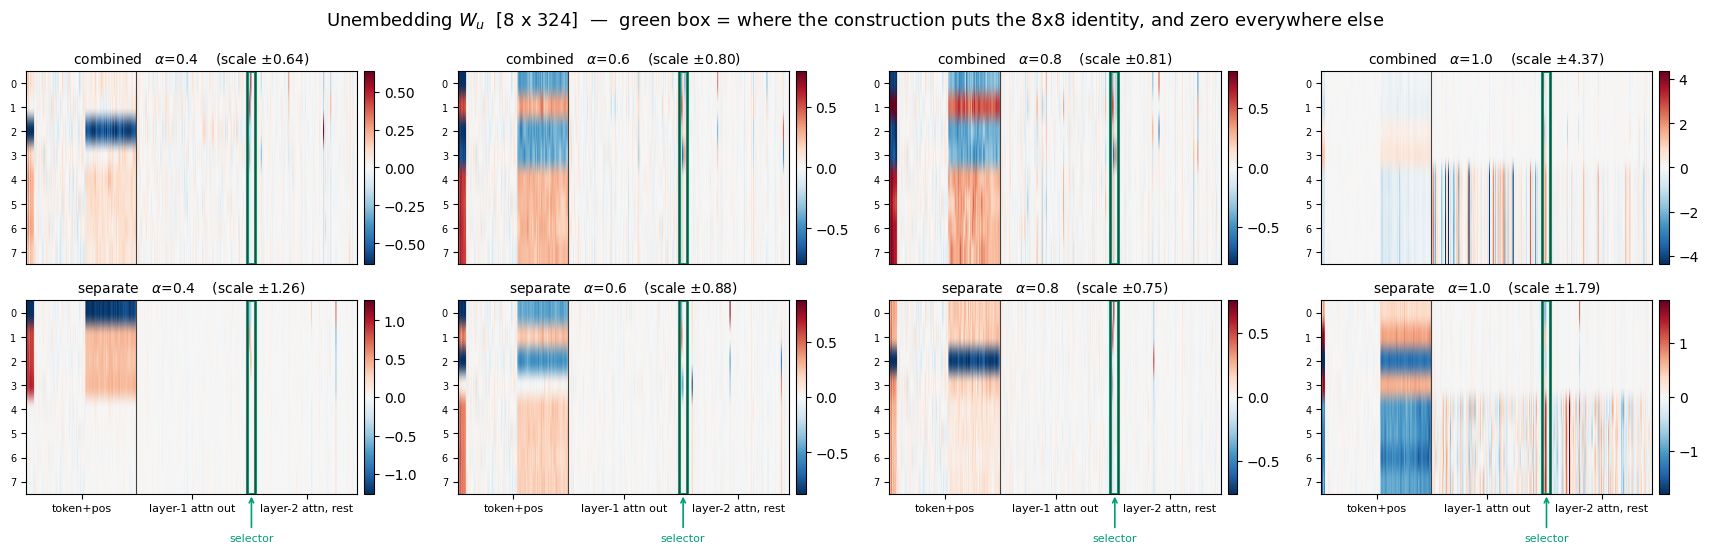

In [2]:
# ── the whole unembedding, one panel per (arch, alpha) ──────────────────────────────────
# Per-panel colour limits (99.5th percentile of |w|): the alpha=1.0 runs carry ~5x the weight
# scale of the others, so a single shared scale would render every other panel blank.
fig, axes = plt.subplots(len(ARCHS10), len(THRS10),
                         figsize=(4.3 * len(THRS10), 2.8 * len(ARCHS10)), squeeze=False)
for i, a in enumerate(ARCHS10):
    for j, t in enumerate(THRS10):
        ax = axes[i][j]; W = S10[(a, t)]['W']
        vm = float(np.quantile(np.abs(W), 0.995))
        im = ax.imshow(W, cmap='RdBu_r', vmin=-vm, vmax=vm, aspect='auto')
        for _, lo, hi in REGIONS10[1:]:
            ax.axvline(lo - .5, color='0.25', lw=.8)
        ax.add_patch(plt.Rectangle((IN2 - .5, -.5), V10, V10, fill=False, ec='#009E73', lw=2.2))
        ax.set_title(f'{a}   $\\alpha$={t}    (scale $\\pm${vm:.2f})', fontsize=10)
        ax.set_yticks(range(V10)); ax.set_yticklabels(range(V10), fontsize=7)
        plt.colorbar(im, ax=ax, fraction=.03, pad=.02)
        if i == len(ARCHS10) - 1:
            ax.set_xticks([ATTN // 2, ATTN + ATTN // 2, IN2 + V10 + (D10 - IN2 - V10) // 2])
            ax.set_xticklabels(['token+pos', 'layer-1 attn out', 'layer-2 attn, rest'],
                               fontsize=8)
            ax.annotate('selector', xy=(IN2 + V10 / 2, V10 - .5), xytext=(0, -34),
                        textcoords='offset points', ha='center', fontsize=8, color='#009E73',
                        arrowprops=dict(arrowstyle='->', color='#009E73', lw=1.2))
        else:
            ax.set_xticks([])
fig.suptitle(f'Unembedding $W_u$  [{V10} x {D10}]  —  green box = where the construction puts '
             f'the {V10}x{V10} identity, and zero everywhere else', fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(ART10, 'unembedding_full.png'), dpi=150, bbox_inches='tight')
plt.show()

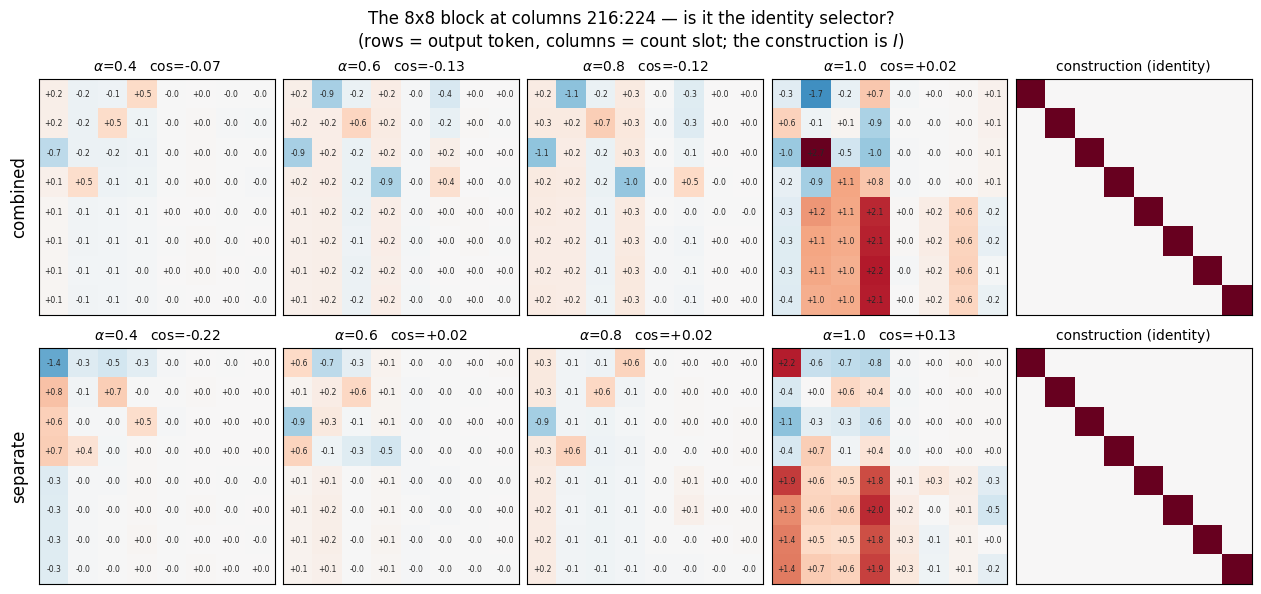

In [3]:
# ── zoom: the block that is supposed to BE the identity ─────────────────────────────────
smax = max(np.abs(S10[k]['sel']).max() for k in S10)
ncol = len(THRS10) + 1
fig, axes = plt.subplots(len(ARCHS10), ncol, figsize=(2.5 * ncol, 2.95 * len(ARCHS10)),
                         squeeze=False, constrained_layout=True)
for i, a in enumerate(ARCHS10):
    for j, t in enumerate(THRS10):
        ax = axes[i][j]
        ax.imshow(S10[(a, t)]['sel'], cmap='RdBu_r', vmin=-smax, vmax=smax)
        ax.set_title(f'$\\alpha$={t}   cos={S10[(a, t)]["cos"]:+.2f}', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(a, fontsize=12, labelpad=8)
        for r in range(V10):
            for cc in range(V10):
                ax.text(cc, r, f'{S10[(a, t)]["sel"][r, cc]:+.1f}', ha='center', va='center',
                        fontsize=5.5, color='0.15')
    ax = axes[i][ncol - 1]
    ax.imshow(I10, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_title('construction (identity)', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'The {V10}x{V10} block at columns {IN2}:{IN2 + V10} — is it the identity '
             f'selector?\n(rows = output token, columns = count slot; the construction is $I$)',
             fontsize=12)
fig.savefig(os.path.join(ART10, 'unembedding_selector.png'), dpi=150, bbox_inches='tight')
plt.show()

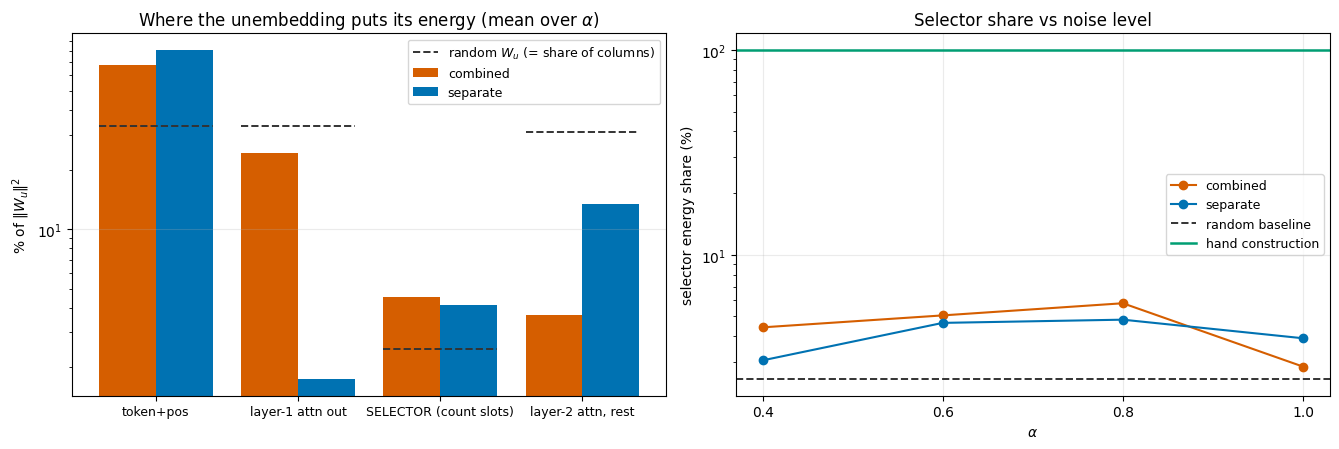

In [4]:
# ── where the energy actually went ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
width = 0.8 / len(ARCHS10)
COLS10 = {'combined': '#D55E00', 'separate': '#0072B2',
          'qk_comb_ov_sep': '#009E73', 'qk_sep_ov_comb': '#CC79A7'}
xs = np.arange(len(REGIONS10))
for i, a in enumerate(ARCHS10):
    m = [100 * np.mean([S10[(a, t)]['eshare'][r] for t in THRS10])
         for r in range(len(REGIONS10))]
    axes[0].bar(xs + i * width - 0.4 + width / 2, m, width, label=a, color=COLS10.get(a, '#666'))
for r, (_, lo, hi) in enumerate(REGIONS10):
    axes[0].plot([xs[r] - 0.4, xs[r] + 0.4], [100 * (hi - lo) / D10] * 2, color='0.2',
                 ls='--', lw=1.4, zorder=5)
axes[0].plot([], [], color='0.2', ls='--', lw=1.4, label='random $W_u$ (= share of columns)')
axes[0].set_xticks(xs); axes[0].set_xticklabels([n for n, _, _ in REGIONS10], fontsize=9)
axes[0].set_ylabel('% of $\\|W_u\\|^2$'); axes[0].set_yscale('log')
axes[0].set_title('Where the unembedding puts its energy (mean over $\\alpha$)')
axes[0].legend(fontsize=9); axes[0].grid(alpha=.25, axis='y')

for a in ARCHS10:
    axes[1].plot(THRS10, [100 * S10[(a, t)]['eshare'][2] for t in THRS10], marker='o',
                 color=COLS10.get(a, '#666'), label=a)
axes[1].axhline(RAND_SHARE10, color='0.2', ls='--', lw=1.4, label='random baseline')
axes[1].axhline(100, color='#009E73', lw=1.8, label='hand construction')
axes[1].set_yscale('log'); axes[1].set_xlabel('$\\alpha$')
axes[1].set_ylabel('selector energy share (%)'); axes[1].set_xticks(THRS10)
axes[1].set_title('Selector share vs noise level'); axes[1].legend(fontsize=9)
axes[1].grid(alpha=.25)
fig.tight_layout()
fig.savefig(os.path.join(ART10, 'unembedding_energy.png'), dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# ── verdict, computed from the numbers above (nothing hard-coded) ───────────────────────
print('=' * 78); print('VERDICT'); print('=' * 78)
for a in ARCHS10:
    sh  = 100 * np.mean([S10[(a, t)]['eshare'][2] for t in THRS10])
    rt  = np.mean([S10[(a, t)]['ratio'] for t in THRS10])
    cs  = np.mean([S10[(a, t)]['cos'] for t in THRS10])
    irr = np.mean([np.mean([S10[(a, t)]['mags'][i] for i in (0, 1, 3)]) for t in THRS10])
    neg = 100 * np.mean([S10[(a, t)]['rr'].get('frac_negative', np.nan) for t in THRS10])
    tok = 100 * np.mean([S10[(a, t)]['eshare'][0] for t in THRS10])
    print(f'{a}:')
    print(f'   selector energy      {sh:6.1f}%   (construction 100%, random {RAND_SHARE10:.1f}%)')
    print(f'   diag/off-diagonal    {rt:6.2f}    (identity inf, no structure 1.0)')
    print(f'   cos(selector, I)     {cs:+6.3f}   (identity +1.000)')
    print(f'   "irrelevant" columns {irr / INIT_ABS10:6.2f}x init magnitude (construction 0)')
    print(f'   token+pos energy     {tok:6.1f}%   (construction 0%)')
    print(f'   readout inputs < 0   {neg:6.1f}%   at the best checkpoint')
    print()
print('ANSWER: no -- and not marginally.')
print('  * The selector block holds only ~3-6% of the energy, barely above the '
      f'{RAND_SHARE10:.1f}% a random')
print('    matrix puts there by virtue of owning that many columns.')
print('  * Inside the block there is no diagonal preference (diag/off ~ 1) and '
      'cos(selector, I) is')
print('    ~0, sometimes NEGATIVE -- it is not a permuted or scaled identity either.')
print('  * The columns the construction sets to zero sit at ~3x their initial magnitude, so GD')
print('    actively RECRUITED them rather than pruning them.')
print('  * The dominant region is token+pos, which the construction never reads at all: the')
print('    model is running a direct token/position readout alongside the count channel.')
print()
print('Fixing the log did NOT make GD converge to the hand construction. It also did not make')
print('the model feed the readout count-like inputs: ~50% of the values entering the frozen log')
print('are still negative at the best checkpoint, where the core is a linear passthrough rather')
print('than a log. So the trained network is not a noisy version of the construction -- it is a')
print('different solution that happens to reach a similar cross-entropy.')

VERDICT
combined:
   selector energy         4.5%   (construction 100%, random 2.5%)
   diag/off-diagonal      1.14    (identity inf, no structure 1.0)
   cos(selector, I)     -0.072   (identity +1.000)
   "irrelevant" columns   3.15x init magnitude (construction 0)
   token+pos energy       67.5%   (construction 0%)
   readout inputs < 0     50.1%   at the best checkpoint

separate:
   selector energy         4.1%   (construction 100%, random 2.5%)
   diag/off-diagonal      1.41    (identity inf, no structure 1.0)
   cos(selector, I)     -0.014   (identity +1.000)
   "irrelevant" columns   2.81x init magnitude (construction 0)
   token+pos energy       80.8%   (construction 0%)
   readout inputs < 0     53.8%   at the best checkpoint

ANSWER: no -- and not marginally.
  * The selector block holds only ~3-6% of the energy, barely above the 2.5% a random
    matrix puts there by virtue of owning that many columns.
  * Inside the block there is no diagonal preference (diag/off ~ 1) and c